# Лабораторная работа № 2

## Обучение нейросетевых моделей для анализа и прогнозирования временных рядов

### Вариант 7

## Цель работы

Получить практические навыки подготовки временных рядов и построения нейросетевых регрессионных моделей для прогнозирования метеорологических показателей. Исследовать возможности полносвязных сетей прямого распространения (MLP), рекуррентных сетей SimpleRNN, а также сетей с ячейками LSTM.

## Задание

- получить исторические ежедневные метеорологические данные для назначенного города и выполнить их первичный анализ;
- сформировать обучающие примеры методом скользящего временного окна;
- реализовать четыре типа регрессионных моделей: MLP, SimpleRNN, LSTM и модель с двумя последовательными слоями LSTM;
- решить две задачи: прогноз температуры на следующий день и прогноз средней температуры за следующие семь дней;
- исследовать влияние длины входного окна, числа нейронов и ячеек, глубины сети, оптимизатора и Dropout;
- сравнить модели с наивными прогнозами, оценить качество на тестовом интервале и проанализировать переобучение.

## Настройка

In [1]:
import os
from pathlib import Path

# Бэкенд Keras
os.environ["KERAS_BACKEND"] = "torch"

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings("ignore", message=".*RNN module weights.*")

# Одно значение для всех ноутбуков, чтобы результаты воспроизводились
SEED = 42
keras.utils.set_random_seed(SEED)

# Ноутбук лежит в labs/labN/src, поэтому пути строим от него
LAB_DIR = Path.cwd().parent
DATA_DIR = LAB_DIR.parent / "data"
FIGURES_DIR = LAB_DIR / "figures"
RESULTS_DIR = LAB_DIR / "results"
MODELS_DIR = LAB_DIR / "models"
for output_dir in (FIGURES_DIR, RESULTS_DIR, MODELS_DIR):
    output_dir.mkdir(exist_ok=True)

# Крупный шрифт: графики должны читаться на слайдах
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 200, "font.size": 12, "axes.grid": True})

In [2]:
# Дополнительные библиотеки: метрики, масштабирование, время обучения, тепловая карта
import time

import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

## Описание набора данных

- Источник: Meteostat, bulk-выгрузка ежедневных наблюдений, https://dev.meteostat.net/bulk/daily.html
- Станция: 37171, Adler (Адлер, район Сочи), WMO 37171, ICAO URSS
- Координаты станции: 43.4333 с.ш., 39.9000 в.д., высота 16 м
- Часовой пояс: Europe/Moscow
- Период: 2016-01-01 ... 2025-12-31, 3653 календарных дня
- Целевой показатель: `tavg`, среднесуточная температура воздуха, °C

Open-Meteo archive на момент выполнения работы отвечал ошибкой 503, поэтому использован другой открытый источник, который допускается заданием. Станция Адлер находится в городском округе Сочи, ряд полный по целевому показателю.

Таблица полей:

| Поле | Содержание | Единица |
|---|---|---|
| date | дата наблюдения | - |
| tavg | среднесуточная температура воздуха | °C |
| tmin | минимальная температура воздуха за сутки | °C |
| tmax | максимальная температура воздуха за сутки | °C |
| prcp | сумма осадков за сутки | мм |
| snow | высота снежного покрова | мм |
| wdir | среднее направление ветра | градусы |
| wspd | средняя скорость ветра | км/ч |
| wpgt | максимальный порыв ветра | км/ч |
| pres | атмосферное давление на уровне станции | гПа |
| tsun | продолжительность солнечного сияния | мин |

В базовом эксперименте используется только история `tavg`. Остальные признаки приведены для описания набора и матрицы корреляций.

In [3]:
# Файл скачан заранее: папка labs/data
DATA_FILE = DATA_DIR / "sochi-weather" / "sochi-daily-meteostat-2016-2025.csv"

if not DATA_FILE.exists():
    raise FileNotFoundError(
        "Не найден файл с данными: " + str(DATA_FILE) + "\n"
        "Скачайте daily-выгрузку Meteostat для станции 37171: "
        "https://bulk.meteostat.net/v2/daily/37171.csv.gz\n"
        "Оставьте столбцы date, tavg, tmin, tmax, prcp, snow, wdir, wspd, wpgt, pres, tsun "
        "и сохраните файл как sochi-daily-meteostat-2016-2025.csv."
    )

weather = pd.read_csv(DATA_FILE, parse_dates=["date"], encoding="utf-8")
weather = weather.sort_values("date").reset_index(drop=True)

print("Размер таблицы:", weather.shape)
display(weather.head(10))
weather.info()
display(weather.describe().T.round(2))

Размер таблицы: (3653, 11)


,date,tavg,tmin,tmax,prcp,snow,wdir,wspd,wpgt,pres,tsun
0,2016-01-01,-1.8,-5.0,1.5,0.8,10.0,353.0,10.7,NaN,NaN,NaN
1,2016-01-02,-1.6,-6.5,2.7,0.0,NaN,25.0,9.8,NaN,NaN,NaN
2,2016-01-03,-2.4,-6.0,0.4,8.9,51.0,15.0,9.6,NaN,NaN,NaN
3,2016-01-04,1.4,-7.0,6.0,0.5,99.0,82.0,20.0,NaN,NaN,NaN
4,2016-01-05,8.9,3.4,13.0,NaN,NaN,120.0,25.8,NaN,NaN,NaN
5,2016-01-06,7.8,6.0,11.1,10.9,NaN,87.0,14.4,NaN,NaN,NaN
6,2016-01-07,12.1,6.4,17.0,NaN,NaN,82.0,17.6,NaN,NaN,NaN
7,2016-01-08,10.3,6.0,16.1,13.5,NaN,18.0,20.4,NaN,NaN,NaN
8,2016-01-09,5.6,4.0,7.4,23.1,NaN,NaN,8.6,NaN,NaN,NaN
9,2016-01-10,5.9,3.0,10.0,5.1,NaN,67.0,12.6,NaN,NaN,NaN


<class 'pandas.DataFrame'>
RangeIndex: 3653 entries, 0 to 3652
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    3653 non-null   datetime64[us]
 1   tavg    3653 non-null   float64       
 2   tmin    3653 non-null   float64       
 3   tmax    3652 non-null   float64       
 4   prcp    3452 non-null   float64       
 5   snow    24 non-null     float64       
 6   wdir    3394 non-null   float64       
 7   wspd    3628 non-null   float64       
 8   wpgt    0 non-null      float64       
 9   pres    3554 non-null   float64       
 10  tsun    0 non-null      float64       
dtypes: datetime64[us](1), float64(10)
memory usage: 314.1 KB


,count,mean,min,25%,50%,75%,max,std
date,3653,2020-12-31 00:00:00,2016-01-01 00:00:00,2018-07-02 00:00:00,2020-12-31 00:00:00,2023-07-02 00:00:00,2025-12-31 00:00:00,NaN
tavg,3653.0,15.185053,-3.4,9.3,14.6,21.8,29.3,7.186957
tmin,3653.0,11.34536,-7.0,5.8,10.8,18.0,26.0,7.062704
tmax,3652.0,19.731216,0.4,13.7,19.7,26.3,36.5,7.42543
prcp,3452.0,3.98511,0.0,0.0,0.0,2.0,111.0,9.856567
snow,24.0,50.875,10.0,20.0,41.0,84.0,150.0,39.52689
wdir,3394.0,130.811727,0.0,49.0,82.0,211.25,359.0,116.958555
wspd,3628.0,11.649421,3.8,9.8,11.4,13.2,29.7,2.942219
wpgt,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pres,3554.0,1015.388351,996.2,1010.9,1015.0,1019.6,1034.5,6.040176


## Анализ данных

### Проверка календаря, пропусков и дубликатов

In [4]:
# Строим полный календарь и проверяем, что каждый день присутствует ровно один раз
expected_dates = pd.date_range(weather["date"].min(), weather["date"].max(), freq="D")
missing_dates = expected_dates.difference(weather["date"])
duplicate_dates = int(weather["date"].duplicated().sum())

print("Первый день:", weather["date"].min().date())
print("Последний день:", weather["date"].max().date())
print("Ожидалось дней:", len(expected_dates))
print("Фактически строк:", len(weather))
print("Пропущенных календарных дней:", len(missing_dates))
print("Дубликатов дат:", duplicate_dates)

missing = weather.isna().sum().to_frame(name="пропусков")
missing["доля, %"] = (missing["пропусков"] / len(weather) * 100).round(2)
display(missing)

Первый день: 2016-01-01
Последний день: 2025-12-31
Ожидалось дней: 3653
Фактически строк: 3653
Пропущенных календарных дней: 0
Дубликатов дат: 0


,пропусков,"доля, %"
date,0,0.00
tavg,0,0.00
tmin,0,0.00
tmax,1,0.03
prcp,201,5.50
snow,3629,99.34
wdir,259,7.09
wspd,25,0.68
wpgt,3653,100.00
pres,99,2.71


**Результат:** пропусков и дубликатов в данных нет.

### Выбросы в целевом показателе

Выбросы ищем по правилу 1,5 межквартильного размаха. Для температуры экстремальные, но реальные значения не удаляем: это погодные аномалии, а не ошибки ввода. Решение объясняется в выводе по анализу.

In [5]:
# Выбросы по правилу 1,5 IQR: считаем границы, но реальные аномалии не удаляем
q1 = weather["tavg"].quantile(0.25)
q3 = weather["tavg"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outliers = weather[(weather["tavg"] < lower_bound) | (weather["tavg"] > upper_bound)]

print("Q1 =", round(float(q1), 2), "Q3 =", round(float(q3), 2), "IQR =", round(float(iqr), 2))
print("Границы:", round(float(lower_bound), 2), "..", round(float(upper_bound), 2))
print("Выбросов:", len(outliers))
display(outliers[["date", "tavg"]].head(10))

Q1 = 9.3 Q3 = 21.8 IQR = 12.5
Границы: -9.45 .. 40.55
Выбросов: 0


,date,tavg


**Результат:** выбросов нет.

### График временного ряда

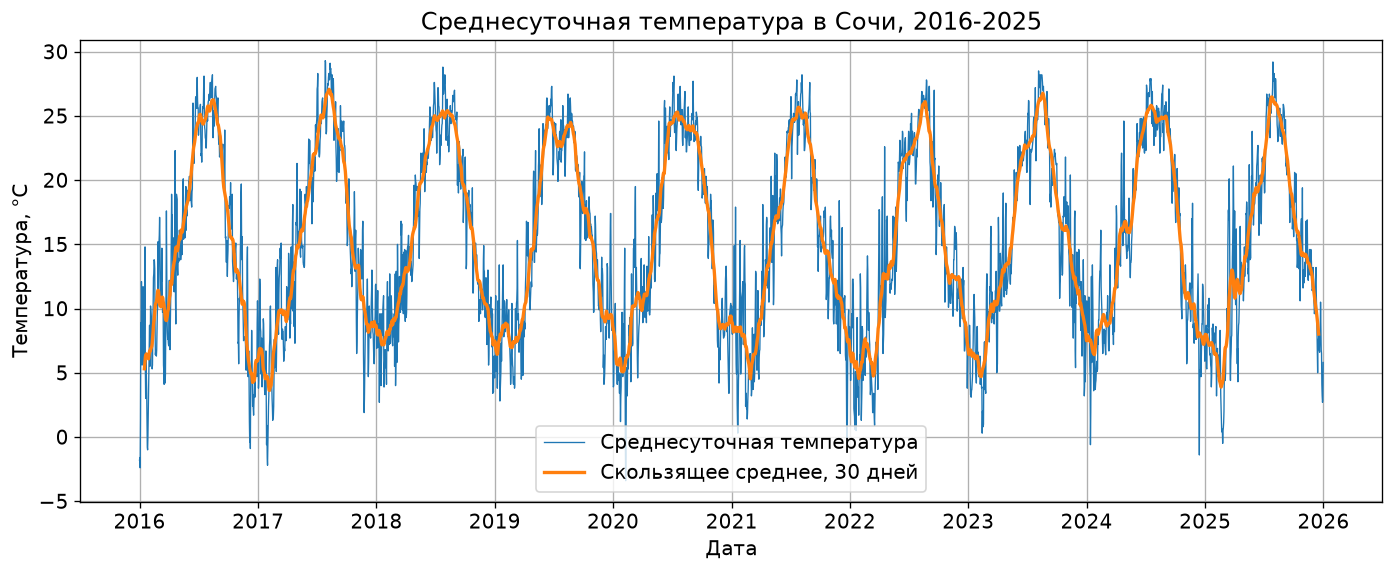

In [6]:
# Ряд целиком и сглаженное скользящее среднее за 30 дней
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(weather["date"], weather["tavg"], color="tab:blue", linewidth=0.8, label="Среднесуточная температура")
ax.plot(
    weather["date"],
    weather["tavg"].rolling(30, center=True).mean(),
    color="tab:orange",
    linewidth=2,
    label="Скользящее среднее, 30 дней",
)
ax.set_title("Среднесуточная температура в Сочи, 2016-2025")
ax.set_xlabel("Дата")
ax.set_ylabel("Температура, °C")
ax.legend()
fig.savefig(FIGURES_DIR / "lab2-series.png", bbox_inches="tight")
plt.show()

**Результат:** Выражен годовой цикл; диапазон -3,4 ... 29,3 °C, среднее 15,19 °C. Межгодовой тренд слабый.

### Сезонность и годовой ход

Ящики с усами по месяцам показывают годовой цикл. Отдельная таблица средних значений по годам нужна, чтобы увидеть межгодовые различия: тест должен быть сопоставим по сезону с обучением.

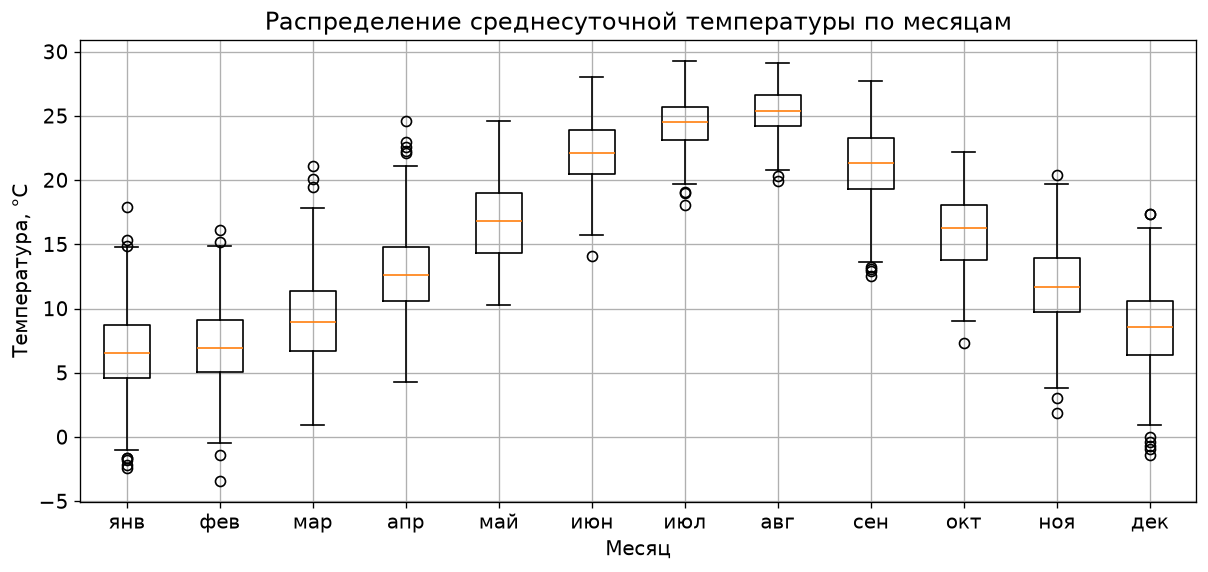

,"средняя температура, °C"
date,
2016,14.83
2017,14.94
2018,16.19
2019,15.48
2020,15.38
2021,14.69
2022,14.51
2023,15.29
2024,15.69


In [7]:
# Сезонность: распределение температуры по месяцам и средние по годам
weather["month"] = weather["date"].dt.month
month_names = ["янв", "фев", "мар", "апр", "май", "июн", "июл", "авг", "сен", "окт", "ноя", "дек"]
monthly = [weather.loc[weather["month"] == month, "tavg"].to_numpy() for month in range(1, 13)]

fig, ax = plt.subplots(figsize=(12, 5))
ax.boxplot(monthly, tick_labels=month_names, showfliers=True)
ax.set_title("Распределение среднесуточной температуры по месяцам")
ax.set_xlabel("Месяц")
ax.set_ylabel("Температура, °C")
fig.savefig(FIGURES_DIR / "lab2-monthly-box.png", bbox_inches="tight")
plt.show()

annual_mean = weather.groupby(weather["date"].dt.year)["tavg"].mean().round(2)
display(annual_mean.to_frame("средняя температура, °C"))

**Результат:** боксплот подтверждает выраженную сезонность: медианные температуры минимальны в январе-феврале (около +6...+7 °C) и максимальны в августе (около +25...+26 °C), ход медиан по месяцам гладкий, близкий к синусоиде. Внутри месячная изменчивость неоднородна: зимой и в переходные месяцы (март, апрель, октябрь, ноябрь, декабрь) разброс наибольший (IQR около 4-5 °C, усы до −3...+1 °C), летом в июле-августе - наименьший (IQR около 2-3 °C), т.е. зима "неустойчивее" лета. В большинстве месяцев присутствуют единичные выбросы (точки) - короткие аномальные потепления и похолодания, согласующиеся с выводом об отсутствии грубых ошибок в данных.

### Корреляции и автокорреляция

Матрица корреляций показывает, насколько дополнительные погодные признаки связаны с целевым показателем. Автокорреляция объясняет, почему наивный прогноз является сильным конкурентом и почему окно длины 7-60 дней содержит полезную информацию.

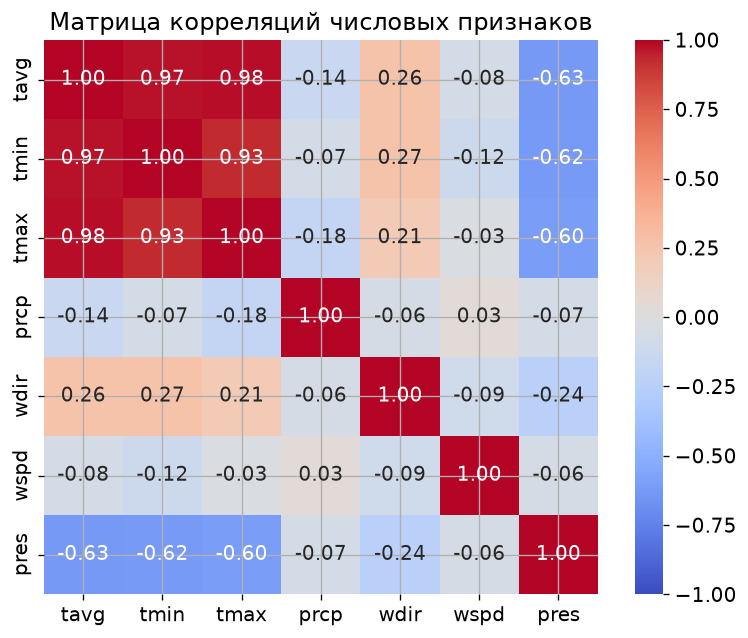

In [8]:
# Корреляционная матрица: какие признаки связаны с целевой температурой
numeric_columns = ["tavg", "tmin", "tmax", "prcp", "wdir", "wspd", "pres"]
corr = weather[numeric_columns].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Матрица корреляций числовых признаков")
fig.savefig(FIGURES_DIR / "lab2-correlation.png", bbox_inches="tight")
plt.show()

**Результат:** целевой признак tavg почти полностью определяется температурами tmin и tmax (r = 0.97 и 0.98 - мультиколлинеарность, их лучше не подавать вместе как независимые признаки), умеренно отрицательно связан с давлением pres (r = −0.63, отражает сезонную связь: тёплый сезон - пониженное давление) и слабо - с направлением ветра wdir (r = 0.26). Осадки prcp и скорость ветра wspd с температурой практически не связаны (|r| ≤ 0.18), как и между собой, т.е. как предикторы температуры они малоинформативны.

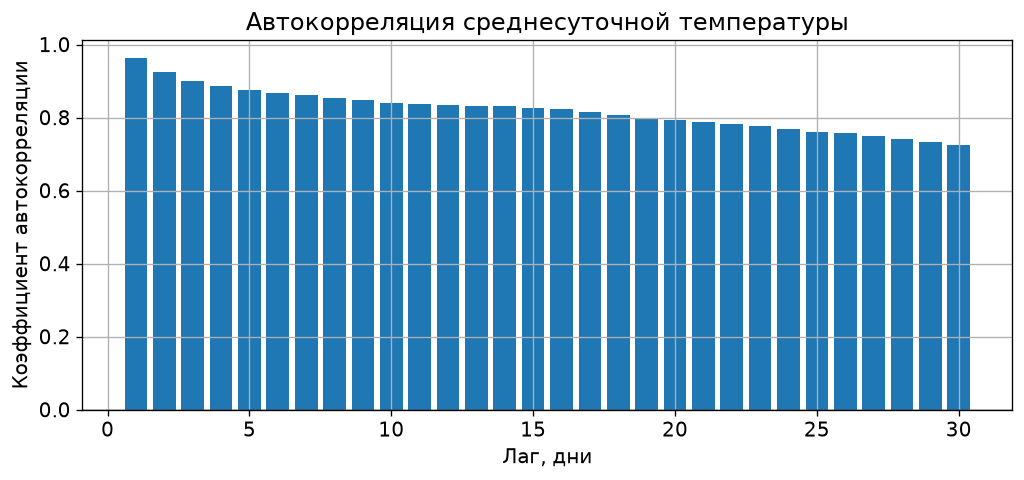

Автокорреляция при лаге 1: 0.964
Автокорреляция при лаге 7: 0.86
Автокорреляция при лаге 30: 0.726


In [9]:
# Автокорреляция: насколько прошлые значения полезны для прогноза
lags = np.arange(1, 31)
acf = np.array([weather["tavg"].autocorr(lag=int(lag)) for lag in lags])

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(lags, acf, color="tab:blue")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Автокорреляция среднесуточной температуры")
ax.set_xlabel("Лаг, дни")
ax.set_ylabel("Коэффициент автокорреляции")
fig.savefig(FIGURES_DIR / "lab2-autocorrelation.png", bbox_inches="tight")
plt.show()

print("Автокорреляция при лаге 1:", round(float(acf[0]), 3))
print("Автокорреляция при лаге 7:", round(float(acf[6]), 3))
print("Автокорреляция при лаге 30:", round(float(acf[29]), 3))

**Результат:** автокорреляция среднесуточной температуры затухает очень медленно: 0.964 на лаге 1, 0.86 на лаге 7 и 0.726 на лаге 30. Это означает сильную инерционность ряда: значение за предыдущий день почти полностью определяет текущее, поэтому наивный прогноз ("завтра как сегодня") - сильный базовый конкурент, а скользящее окно длиной 7-60 дней действительно содержит полезную информацию для модели; высокое значение на лаге 30 также отражает вклад сезонной составляющей.

## Подготовка данных

### Две задачи прогнозирования

Для момента времени t входом служит последовательность предыдущих значений температуры:

$$X_t = [T(t-L), T(t-L+1), \ldots, T(t-1)]$$

Задача A, прогноз на следующий день:

$$y_t = T(t)$$

Задача B, прогноз среднего за следующие семь дней:

$$y_t = \frac{1}{7}\sum_{k=0}^{6} T(t+k)$$

Для задачи B модель выдает одно скалярное значение, это прогноз недельного среднего, а не семь отдельных дневных прогнозов.

### Разбиение по времени

Данные делятся строго хронологически: 70% train, 15% validation, 15% test. Более поздние даты всегда попадают в validation и test. При формировании окон целевой интервал должен полностью лежать внутри своей выборки. Поэтому окна, которые пересекают границу, отбрасываются, и для задачи B автоматически возникает зазор не меньше семи дней.

In [10]:
# Хронологическое разбиение 70/15/15: перемешивать временной ряд нельзя
n_days = len(weather)
train_size = int(n_days * 0.70)
val_size = int(n_days * 0.15)

train_end = weather.loc[train_size - 1, "date"]
val_start = weather.loc[train_size, "date"]
val_end = weather.loc[train_size + val_size - 1, "date"]
test_start = weather.loc[train_size + val_size, "date"]
test_end = weather.loc[n_days - 1, "date"]

split_table = pd.DataFrame({
    "Выборка": ["train", "validation", "test"],
    "Начало": [weather.loc[0, "date"], val_start, test_start],
    "Конец": [train_end, val_end, test_end],
    "Дней": [train_size, val_size, n_days - train_size - val_size],
})
display(split_table)
split_table.to_csv(RESULTS_DIR / "lab2-splits.csv", index=False, encoding="utf-8")

,Выборка,Начало,Конец,Дней
0,train,2016-01-01,2022-12-31,2557
1,validation,2023-01-01,2024-06-30,547
2,test,2024-07-01,2025-12-31,549


train: 2557 дней, средняя температура 15.15 °C, диапазон -3.4 ... 29.3 °C
validation: 547 дней, средняя температура 14.71 °C, диапазон -0.6 ... 28.5 °C
test: 549 дней, средняя температура 15.84 °C, диапазон -1.4 ... 29.2 °C


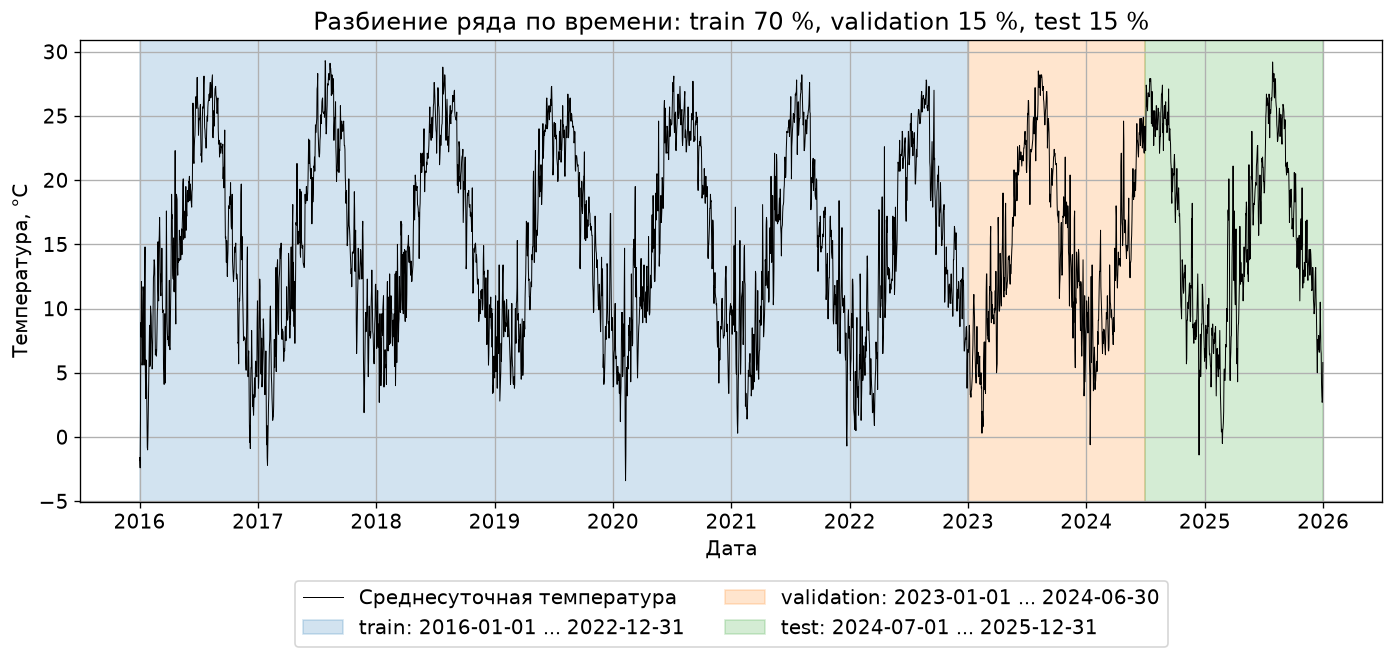

In [11]:
import matplotlib.dates as mdates

# Ряд с закрашенными интервалами train, validation и test: видно, что
# выборки идут друг за другом по времени и самые поздние даты отложены для проверки
split_periods = [
    ("train", weather.loc[0, "date"], train_end, "tab:blue"),
    ("validation", val_start, val_end, "tab:orange"),
    ("test", test_start, test_end, "tab:green"),
]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(weather["date"], weather["tavg"], color="black", linewidth=0.6, label="Среднесуточная температура")
for split_name, period_start, period_end, period_color in split_periods:
    # Закрашиваем интервал до конца последнего дня, чтобы между выборками не было щели
    ax.axvspan(period_start, period_end + pd.Timedelta(days=1), color=period_color, alpha=0.2,
               label=f"{split_name}: {period_start:%Y-%m-%d} ... {period_end:%Y-%m-%d}")

# Средняя температура и диапазон каждой выборки: test не должен выходить за значения, известные по train
for split_name, period_start, period_end, _ in split_periods:
    period_tavg = weather.loc[weather["date"].between(period_start, period_end), "tavg"]
    print(f"{split_name}: {len(period_tavg)} дней, средняя температура {period_tavg.mean():.2f} °C, "
          f"диапазон {period_tavg.min()} ... {period_tavg.max()} °C")

ax.set_title("Разбиение ряда по времени: train 70 %, validation 15 %, test 15 %")
ax.set_xlabel("Дата")
ax.set_ylabel("Температура, °C")
# Подпись года под каждой отметкой, как на графике всего ряда
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
# Легенда под графиком, чтобы не закрывать данные
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
fig.savefig(FIGURES_DIR / "lab2-splits.png", bbox_inches="tight")
plt.show()

**Результат:** выборки идут подряд и не пересекаются, самые поздние даты отложены для validation и test. Validation и test длятся по полтора года, поэтому в каждой есть все сезоны. Средняя температура: train 15,15 °C, validation 14,71 °C, test 15,84 °C. Test немного теплее, потому что в нем два лета и одна зима. Значения test (-1,4 ... 29,2 °C) лежат внутри диапазона train (-3,4 ... 29,3 °C): модели не нужно прогнозировать температуру, которой не было при обучении.

### Масштабирование

`StandardScaler` обучается только на обучающем интервале. Затем те же среднее и стандартное отклонение применяются к validation и test. Это исключает утечку информации из будущего. Для интерпретации метрик прогнозы возвращаются в градусы Цельсия.

In [12]:
# Масштабирование обучаем только на train, чтобы не подглядывать в val/test
scaler = StandardScaler()
train_mask_raw = weather["date"] <= train_end
scaler.fit(weather.loc[train_mask_raw, ["tavg"]])
weather["tavg_scaled"] = scaler.transform(weather[["tavg"]]).ravel()

train_tavg = weather.loc[train_mask_raw, "tavg"]
print("Среднее на train, °C:", round(float(scaler.mean_[0]), 3))
print("Стандартное отклонение на train, °C:", round(float(scaler.scale_[0]), 3))
print("Диапазон train, °C:", round(float(train_tavg.min()), 2), "..", round(float(train_tavg.max()), 2))

Среднее на train, °C: 15.147
Стандартное отклонение на train, °C: 7.227
Диапазон train, °C: -3.4 .. 29.3


### Скользящие окна

Функция ниже строит окна для выбранной задачи и длины окна. Внутри сохраняются и масштабированные значения для нейросетей, и исходные градусы для наивных прогнозов и метрик. Разбиение выполняется по целевому интервалу, а не по началу окна.

In [13]:
# Перебираемые длины скользящего окна, дни
WINDOW_LENGTHS = [7, 14, 30, 60]
# Горизонт задачи B: среднее за следующие 7 дней
WEEKLY_HORIZON = 7
# Две задачи: температура следующего дня и среднее за неделю
TASKS = ["next_day", "weekly_mean"]
TASK_TITLES = {
    "next_day": "прогноз на следующий день",
    "weekly_mean": "прогноз среднего за 7 дней",
}
MODEL_TITLES = {
    "MLP": "MLP",
    "SimpleRNN": "SimpleRNN",
    "LSTM": "LSTM",
    "StackedLSTM": "Stacked LSTM",
}


def make_task_data(task, window):
    '''Строит окна и размечает их по выборкам train, val, test, gap.'''
    values_scaled = weather["tavg_scaled"].to_numpy(dtype="float32")
    values_raw = weather["tavg"].to_numpy(dtype="float32")
    dates = pd.DatetimeIndex(weather["date"])
    horizon = 1 if task == "next_day" else WEEKLY_HORIZON

    X_scaled, X_raw, y_scaled, y_raw = [], [], [], []
    target_start, target_end = [], []

    # Для каждого t вход - L прошлых дней, цель - день t или среднее t..t+6
    last_start = len(weather) - horizon
    for i in range(window, last_start + 1):
        X_scaled.append(values_scaled[i - window:i])
        X_raw.append(values_raw[i - window:i])
        if task == "next_day":
            y_scaled.append(values_scaled[i])
            y_raw.append(values_raw[i])
        else:
            y_scaled.append(values_scaled[i:i + horizon].mean())
            y_raw.append(values_raw[i:i + horizon].mean())
        target_start.append(dates[i])
        target_end.append(dates[i + horizon - 1])

    X_scaled = np.asarray(X_scaled, dtype="float32")
    X_raw = np.asarray(X_raw, dtype="float32")
    y_scaled = np.asarray(y_scaled, dtype="float32")
    y_raw = np.asarray(y_raw, dtype="float32")
    target_start = pd.DatetimeIndex(target_start)
    target_end = pd.DatetimeIndex(target_end)

    # Размечаем окна по датам цели; окна на стыке выборок попадают в gap
    split = np.full(len(y_scaled), "gap", dtype=object)
    split[target_end <= train_end] = "train"
    split[(target_start >= val_start) & (target_end <= val_end)] = "val"
    split[target_start >= test_start] = "test"

    return {
        "task": task,
        "window": window,
        "X": X_scaled,
        "y": y_scaled,
        "X_raw": X_raw,
        "y_raw": y_raw,
        "target_start": target_start,
        "target_end": target_end,
        "split": split,
    }

In [14]:
# Проверяем размеры выборок и точные даты целевых интервалов
split_rows = []
for task in TASKS:
    for window in WINDOW_LENGTHS:
        data = make_task_data(task, window)
        for split_name in ["train", "val", "test", "gap"]:
            mask = data["split"] == split_name
            split_rows.append({
                "task": task,
                "window": window,
                "split": split_name,
                "окон": int(mask.sum()),
                "первая цель": data["target_start"][mask].min() if mask.any() else pd.NaT,
                "последняя цель": data["target_end"][mask].max() if mask.any() else pd.NaT,
            })
split_check = pd.DataFrame(split_rows)
display(split_check.head(12))
split_check.to_csv(RESULTS_DIR / "lab2-window-counts.csv", index=False, encoding="utf-8")

# Явная проверка отсутствия пересечения целевых интервалов между выборками
for task in TASKS:
    data = make_task_data(task, max(WINDOW_LENGTHS))
    train_last = data["target_end"][data["split"] == "train"].max()
    val_first = data["target_start"][data["split"] == "val"].min()
    val_last = data["target_end"][data["split"] == "val"].max()
    test_first = data["target_start"][data["split"] == "test"].min()
    print(task)
    print("  последняя цель train:", train_last.date())
    print("  первая цель val:  ", val_first.date())
    print("  последняя цель val:", val_last.date())
    print("  первая цель test: ", test_first.date())
    assert train_last < val_first, "Целевые интервалы train и val пересекаются"
    assert val_last < test_first, "Целевые интервалы val и test пересекаются"
print("Проверка пройдена: целевые интервалы выборок не пересекаются.")

,task,window,split,окон,первая цель,последняя цель
0,next_day,7,train,2550,2016-01-08,2022-12-31
1,next_day,7,val,547,2023-01-01,2024-06-30
2,next_day,7,test,549,2024-07-01,2025-12-31
3,next_day,7,gap,0,NaT,NaT
4,next_day,14,train,2543,2016-01-15,2022-12-31
5,next_day,14,val,547,2023-01-01,2024-06-30
6,next_day,14,test,549,2024-07-01,2025-12-31
7,next_day,14,gap,0,NaT,NaT
8,next_day,30,train,2527,2016-01-31,2022-12-31
9,next_day,30,val,547,2023-01-01,2024-06-30


next_day
  последняя цель train: 2022-12-31
  первая цель val:   2023-01-01
  последняя цель val: 2024-06-30
  первая цель test:  2024-07-01
weekly_mean
  последняя цель train: 2022-12-31
  первая цель val:   2023-01-01
  последняя цель val: 2024-06-30
  первая цель test:  2024-07-01
Проверка пройдена: целевые интервалы выборок не пересекаются.


## Базовая модель

В качестве базовой модели используются наивные прогнозы, с которыми сравниваются нейросети:

- persistence: для задачи A прогноз равен последнему известному значению, для задачи B - среднему за последние семь известных дней;
- seasonal naive: прогноз равен значению того же календарного дня год назад, для задачи B усредняются семь таких дней. Для 29 февраля используется ближайший доступный день год назад, pandas `DateOffset(years=1)` переводит его в 28 февраля.

Наивные прогнозы не обучаются, поэтому их метрики на validation служат ориентиром, который нейросеть должна превзойти.

In [15]:
raw_series = weather.set_index("date")["tavg"]


# Базовые прогнозы: persistence (последнее значение) и seasonal naive (год назад)
def seasonal_value(day):
    '''Возвращает температуру в тот же календарный день год назад.'''
    try:
        return float(raw_series.loc[day - pd.DateOffset(years=1)])
    except KeyError:
        return np.nan


def naive_predictions(data, method):
    '''Считает наивный прогноз в градусах Цельсия для всех окон задачи.'''
    if method == "persistence":
        if data["task"] == "next_day":
            return data["X_raw"][:, -1]
        return data["X_raw"][:, -7:].mean(axis=1)

    if method == "seasonal":
        predictions = []
        for start, end in zip(data["target_start"], data["target_end"]):
            days = pd.date_range(start, end, freq="D")
            values = np.array([seasonal_value(day) for day in days], dtype=float)
            predictions.append(np.nanmean(values) if np.any(np.isfinite(values)) else np.nan)
        return np.asarray(predictions, dtype="float32")

    raise ValueError("Неизвестный метод: " + str(method))


# Единые метрики MAE, MSE, RMSE, R2 для всех моделей и базовых прогнозов
def calc_metrics(y_true, y_pred):
    '''Считает MAE, MSE, RMSE и R2 в исходных единицах, пропуски отбрасывает.'''
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true = y_true[mask]
    y_pred = y_pred[mask]
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": float(np.sqrt(mse)),
        "R2": r2_score(y_true, y_pred),
        "n": int(mask.sum()),
    }


naive_rows = []
for task in TASKS:
    data = make_task_data(task, min(WINDOW_LENGTHS))
    mask = data["split"] == "val"
    for method, title in [("persistence", "Naive (persistence)"), ("seasonal", "Seasonal naive")]:
        metrics = calc_metrics(data["y_raw"][mask], naive_predictions(data, method)[mask])
        naive_rows.append({"task": task, "model": title, **metrics})

naive_validation = pd.DataFrame(naive_rows)
display(naive_validation.round(4))
naive_validation.round(4).to_csv(RESULTS_DIR / "lab2-naive-validation.csv", index=False, encoding="utf-8")

,task,model,MAE,MSE,RMSE,R2,n
0,next_day,Naive (persistence),1.3309,3.7069,1.9253,0.9199,547
1,next_day,Seasonal naive,3.0530,16.0851,4.0106,0.6526,547
2,weekly_mean,Naive (persistence),1.8673,5.4214,2.3284,0.8727,541
3,weekly_mean,Seasonal naive,2.2133,8.7043,2.9503,0.7956,541


**Результат:** на validation persistence дает RMSE 1,9253 °C и R2 0,9199 для следующего дня, а для недельного среднего - RMSE 2,3284 °C и R2 0,8727. Seasonal naive заметно хуже: RMSE 4,0106 °C (R2 0,6526) и 2,9503 °C (R2 0,7956). Persistence - сильный базовый прогноз, потому что температура сильно автокоррелирована: коэффициент автокорреляции при лаге 1 равен 0,964.

## Эксперименты

План экспериментов:

1. Для каждой архитектуры перебираются длины окна 7, 14, 30 и 60 дней при 32 нейронах или ячейках. Это показывает влияние длины истории.
2. Для каждой архитектуры число нейронов увеличивается до 64 при лучшей длине окна, выбранной по validation.
3. Для лучшей конфигурации каждой задачи сравниваются оптимизаторы Adam и RMSprop.
4. Отдельно проверяется Dropout 0,2: базовая модель строится без него, регуляризация добавляется только как отдельный эксперимент.
5. Выбранная и самая большая модели обучаются 150 эпох без EarlyStopping, чтобы проверить, нужен ли он.
6. Лучшая конфигурация каждой архитектуры повторяется с пятью разными SEED, чтобы оценить устойчивость результатов.

Все модели обучаются в одинаковых условиях: MSE, batch size 32, до 80 эпох, EarlyStopping с patience 8 и восстановлением лучших весов по validation loss. Выбор архитектуры и гиперпараметров идет только по validation, test используется один раз в конце.

Таблица архитектур:

| Модель | Архитектура |
|---|---|
| MLP | вход - вектор длины L, Dense(units, relu), Dense(1) |
| SimpleRNN | вход (L, 1), SimpleRNN(units), Dense(1) |
| LSTM | вход (L, 1), LSTM(units), Dense(1) |
| Stacked LSTM | вход (L, 1), LSTM(units, return_sequences=True), LSTM(units), Dense(1) |

Выходной слой во всех моделях имеет линейную активацию, так как решается задача регрессии.

In [ ]:
# Общие правила: Adam, lr=0.001, MSE; Dropout выключен по умолчанию
def build_model(model_type, window, units, optimizer_name="adam", dropout=0.0,
                learning_rate=0.001, n_features=1, seed=SEED):
    '''Создает модель выбранного типа с одинаковыми правилами обучения.

    n_features - число признаков в одном дне окна. В основном эксперименте
    признак один (средняя температура), в эксперименте с дополнительными
    погодными признаками - четыре.
    seed задает начальные веса; другое значение нужно только для проверки
    устойчивости, во всех остальных экспериментах используется общий SEED.
    '''
    keras.utils.set_random_seed(seed)

    if model_type == "MLP":
        # MLP получает окно как плоский вектор длины window * n_features
        inputs = keras.Input(shape=(window * n_features,))
        x = keras.layers.Dense(units, activation="relu")(inputs)
        if dropout > 0:
            x = keras.layers.Dropout(dropout)(x)
    else:
        # RNN-модели получают последовательность формы (window, n_features)
        inputs = keras.Input(shape=(window, n_features))
        if model_type == "SimpleRNN":
            x = keras.layers.SimpleRNN(units)(inputs)
        elif model_type == "LSTM":
            x = keras.layers.LSTM(units)(inputs)
        elif model_type == "StackedLSTM":
            x = keras.layers.LSTM(units, return_sequences=True)(inputs)
            x = keras.layers.LSTM(units)(x)
        else:
            raise ValueError("Неизвестная модель: " + str(model_type))
        if dropout > 0:
            x = keras.layers.Dropout(dropout)(x)

    outputs = keras.layers.Dense(1, activation="linear")(x)
    model = keras.Model(inputs, outputs)

    if optimizer_name == "adam":
        optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    elif optimizer_name == "rmsprop":
        optimizer = keras.optimizers.RMSprop(learning_rate=learning_rate)
    else:
        raise ValueError("Неизвестный оптимизатор: " + str(optimizer_name))

    # Для всех архитектур одинаковые функция потерь и метрика
    model.compile(optimizer=optimizer, loss="mse", metrics=["mae"])
    return model


# EarlyStopping по val_loss: patience 8, возврат лучших весов
def train_model(model, X_train, y_train, X_val, y_val, epochs=80, batch_size=32, patience=8,
                use_early_stopping=True):
    '''Обучает модель и возвращает историю, время и callback EarlyStopping.

    use_early_stopping=False нужен только для эксперимента без ранней остановки:
    модель обучается все epochs эпох, callback не создается (возвращается None).
    '''
    callbacks = []
    early_stopping = None
    if use_early_stopping:
        early_stopping = keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=patience,
            restore_best_weights=True,
        )
        callbacks.append(early_stopping)
    started = time.perf_counter()
    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        shuffle=True,
        verbose=0,
        callbacks=callbacks,
    )
    elapsed = time.perf_counter() - started
    return history, elapsed, early_stopping

### Полная архитектура моделей

Ниже - вывод `summary()` для четырёх базовых архитектур на примере L = 14 и 32 нейронов/ячеек: видны состав слоёв, форма выхода и число обучаемых параметров.

In [17]:
# Полная архитектура четырёх базовых моделей (пример: L = 14, units = 32)
for model_name in MODEL_TITLES:
    print("=" * 70)
    print(MODEL_TITLES[model_name] + ": L = 14, units = 32")
    model = build_model(model_name, window=14, units=32)
    model.summary()

    # summary() не показывает активации, поэтому выводим их отдельной строкой
    activations = []
    for layer in model.layers:
        parts = []
        if hasattr(layer, "activation"):
            parts.append(layer.activation.__name__)
        if hasattr(layer, "recurrent_activation"):
            parts.append("recurrent=" + layer.recurrent_activation.__name__)
        if parts:
            activations.append(layer.name + ": " + ", ".join(parts))
    print("Активации по слоям: " + "; ".join(activations))

MLP: L = 14, units = 32


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 14)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 513 (2.00 KB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 0 (0.00 B)

... (15 outputs left out)

 Total params: 12,705 (49.63 KB)

 Trainable params: 12,705 (49.63 KB)

 Non-trainable params: 0 (0.00 B)

Активации по слоям: lstm_1: tanh, recurrent=sigmoid; lstm_2: tanh, recurrent=sigmoid; dense_4: linear


In [18]:
runs = []
trained_models = {}
histories = {}
data_cache = {}


def run_experiment(task, model_type, window, units, optimizer_name="adam", dropout=0.0):
    '''Обучает одну конфигурацию и сохраняет метрики на validation.'''
    # Окна зависят только от задачи и длины окна - кэшируем их
    cache_key = (task, int(window))
    if cache_key not in data_cache:
        data_cache[cache_key] = make_task_data(task, int(window))
    data = data_cache[cache_key]

    model = build_model(model_type, int(window), int(units), optimizer_name, float(dropout))
    mask_train = data["split"] == "train"
    mask_val = data["split"] == "val"

    X_train = data["X"][mask_train]
    X_val = data["X"][mask_val]
    if model_type != "MLP":
        X_train = X_train[..., None]
        X_val = X_val[..., None]

    # Обучение на train, контроль переобучения - на validation
    history, elapsed, early_stopping = train_model(
        model,
        X_train,
        data["y"][mask_train],
        X_val,
        data["y"][mask_val],
    )

    # Метрики считаем в исходных градусах после обратного масштабирования
    pred_scaled = model.predict(X_val, verbose=0).ravel()
    pred = scaler.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()
    metrics = calc_metrics(data["y_raw"][mask_val], pred)

    best_epoch = getattr(early_stopping, "best_epoch", None)
    if best_epoch is None:
        best_epoch = len(history.history["loss"]) - 1

    run_id = len(runs)
    record = {
        "run_id": run_id,
        "task": task,
        "model": model_type,
        "window": int(window),
        "units": int(units),
        "optimizer": optimizer_name,
        "dropout": float(dropout),
        "params": int(model.count_params()),
        "epochs_run": len(history.history["loss"]),
        "best_epoch": int(best_epoch) + 1,
        "train_time_s": round(elapsed, 2),
        "val_MAE": metrics["MAE"],
        "val_MSE": metrics["MSE"],
        "val_RMSE": metrics["RMSE"],
        "val_R2": metrics["R2"],
    }
    runs.append(record)
    trained_models[run_id] = model
    histories[run_id] = history
    return record


def runs_frame():
    '''Возвращает все прогоны таблицей с округленными метриками.'''
    frame = pd.DataFrame(runs)
    for column in ["val_MAE", "val_MSE", "val_RMSE", "val_R2"]:
        frame[column] = frame[column].round(4)
    return frame

### Как читать кривые обучения

Все кривые обучения в работе построены одинаково:

- по оси Y - RMSE в градусах Цельсия. Keras считает loss (MSE) в масштабированных единицах; корень из него, умноженный на стандартное отклонение температуры на train, дает RMSE в °C - ту же метрику, что в таблицах результатов;
- сплошная линия - обучающая выборка, пунктир - валидационная;
- точка на пунктире - лучшая эпоха по валидации: EarlyStopping восстанавливает именно ее веса;
- эпохи нумеруются с 1. Кривая заканчивается через 8 эпох (patience) после лучшей;
- ось Y построена по эпохам начиная со второй. На первой эпохе ошибка в 2-3 раза выше, и при полном масштабе плато, где видно переобучение, сжимается в полосу у дна. Поэтому точка первой эпохи обучающей кривой уходит за верхний край.

Переобучение на таких графиках - это когда сплошная линия продолжает снижаться, а пунктир после лучшей эпохи устойчиво растет.

Пунктир заметно колеблется от эпохи к эпохе, а сплошная линия гладкая. Это не переобучение: валидационная выборка в 4-5 раз меньше обучающей, а соседние окна почти совпадают (у недельного среднего 6 из 7 дней общие), поэтому независимых примеров в ней еще меньше и ее ошибка шумнее. Кроме того, оптимизатор после каждой эпохи оказывается в немного другой точке около минимума. Поэтому EarlyStopping ждет 8 эпох (patience), а не останавливается на первом скачке, и возвращает веса лучшей эпохи. Насколько от этого шума зависит итоговое число, проверяется отдельно, повтором с разными SEED.

In [ ]:
# Единый вид кривых обучения для всех экспериментов
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

# Стандартное отклонение температуры на train: переводит ошибку из
# масштабированных единиц обратно в градусы Цельсия
TEMPERATURE_SCALE = float(scaler.scale_[0])
# Цвета для сравнения двух вариантов на одних осях
BASE_COLOR = "tab:blue"
NEW_COLOR = "tab:orange"


def loss_to_rmse(loss_values):
    """Переводит MSE в масштабированных единицах в RMSE в градусах Цельсия.

    Цель масштабирована как (T - mean) / scale, поэтому ошибка в градусах равна
    ошибке в масштабе, умноженной на scale. Корень из MSE дает RMSE.
    """
    return np.sqrt(np.asarray(loss_values, dtype=float)) * TEMPERATURE_SCALE


def draw_learning_curves(axis, history, color=BASE_COLOR, label_suffix=""):
    """Рисует RMSE на обучении (сплошная) и на валидации (пунктир) по эпохам.

    Точкой отмечена лучшая эпоха по валидации. Возвращает обе кривые и номер
    лучшей эпохи (с 1), чтобы подобрать масштаб оси и подписать график.
    """
    train_rmse = loss_to_rmse(history["loss"])
    val_rmse = loss_to_rmse(history["val_loss"])
    epochs = np.arange(1, len(train_rmse) + 1)

    axis.plot(epochs, train_rmse, color=color, linewidth=2, label="Обучение" + label_suffix)
    axis.plot(epochs, val_rmse, color=color, linewidth=2, linestyle="--",
              label="Валидация" + label_suffix)

    # Лучшая эпоха - минимум ошибки на валидации
    best_index = int(np.argmin(val_rmse))
    axis.plot(epochs[best_index], val_rmse[best_index], marker="o", markersize=9,
              color=color, markeredgecolor="white", markeredgewidth=1.5, linestyle="none")
    return [train_rmse, val_rmse], best_index + 1


BEST_EPOCH_LABEL = "Лучшая эпоха (веса восстановлены)"


def best_marker_handle():
    """Серая точка для легенды: объясняет маркер лучшей эпохи на всех кривых."""
    return Line2D([], [], marker="o", color="gray", markersize=9, markeredgecolor="white",
                  linestyle="none")


def format_curves_axis(axis, title, curves, legend=True):
    """Подписи, целые номера эпох и масштаб оси Y по эпохам со второй.

    legend=False - для рисунков из нескольких панелей: там одна общая легенда
    над панелями (add_figure_legend), чтобы она не закрывала кривые.
    """
    tail_values = np.concatenate([values[1:] for values in curves])
    margin = 0.08 * (tail_values.max() - tail_values.min())
    axis.set_ylim(tail_values.min() - margin, tail_values.max() + margin)
    axis.set_title(title)
    axis.set_xlabel("Эпоха")
    axis.set_ylabel("RMSE, °C")
    axis.xaxis.set_major_locator(MaxNLocator(integer=True))
    if legend:
        # В легенду добавляем серую точку: она объясняет маркер лучшей эпохи
        handles, labels = axis.get_legend_handles_labels()
        handles.append(best_marker_handle())
        labels.append(BEST_EPOCH_LABEL)
        axis.legend(handles, labels, loc="upper right")


def add_figure_legend(fig, axis, marker_label=BEST_EPOCH_LABEL, columns=3):
    """Одна легенда над всеми панелями: линии берутся с одной панели, они везде одинаковые.

    Возвращает верхнюю границу области панелей для tight_layout, чтобы легенда
    и общий заголовок не наезжали на графики.
    """
    handles, labels = axis.get_legend_handles_labels()
    handles.append(best_marker_handle())
    labels.append(marker_label)
    rows = int(np.ceil(len(labels) / columns))
    # Отступы задаем в дюймах и переводим в доли высоты рисунка:
    # 0,45 дюйма - общий заголовок, примерно 0,3 дюйма - строка легенды
    height = fig.get_figheight()
    fig.legend(handles, labels, loc="upper center", ncol=columns, frameon=False,
               bbox_to_anchor=(0.5, 1 - 0.42 / height))
    return 1 - (0.3 + 0.3 * rows) / height


def config_text(record):
    """Короткое описание конфигурации для заголовка панели."""
    return (MODEL_TITLES[record["model"]] + ", L = " + str(int(record["window"]))
            + ", units = " + str(int(record["units"])))


def print_run_summary(label, record):
    """Печатает лучшую эпоху и validation RMSE прогона - те же числа, что в таблицах."""
    print(label + ": лучшая эпоха", int(record["best_epoch"]), "из", int(record["epochs_run"]),
          ", val RMSE =", round(float(record["val_RMSE"]), 4), "°C")


def plot_architecture_curves(model_type):
    """Кривые лучшей по валидации конфигурации архитектуры: обе задачи рядом."""
    current_runs = runs_frame()
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for axis, task in zip(axes, TASKS):
        stage = current_runs[
            (current_runs["task"] == task) & (current_runs["model"] == model_type)
            & (current_runs["units"] == 32) & (current_runs["optimizer"] == "adam")
            & (current_runs["dropout"] == 0)
        ]
        record = stage.sort_values("val_RMSE").iloc[0]
        curves, _ = draw_learning_curves(axis, histories[int(record["run_id"])].history)
        format_curves_axis(axis, TASK_TITLES[task].capitalize() + "\n" + config_text(record), curves,
                           legend=False)
        print_run_summary(TASK_TITLES[task] + ", " + config_text(record), record)

    fig.suptitle("Кривые обучения " + MODEL_TITLES[model_type]
                 + ": лучшая длина окна для каждой задачи")
    fig.tight_layout(rect=[0, 0, 1, add_figure_legend(fig, axes[0])])
    fig.savefig(FIGURES_DIR / ("lab2-curves-" + model_type.lower() + ".png"), bbox_inches="tight")
    plt.show()


def plot_pair_curves(axis, base_record, new_record, base_label, new_label, title):
    """Две конфигурации на одних осях: синий - исходная, оранжевый - измененная."""
    base_curves, _ = draw_learning_curves(axis, histories[int(base_record["run_id"])].history,
                                          BASE_COLOR, ", " + base_label)
    new_curves, _ = draw_learning_curves(axis, histories[int(new_record["run_id"])].history,
                                         NEW_COLOR, ", " + new_label)
    format_curves_axis(axis, title, base_curves + new_curves, legend=False)
    print_run_summary(title.replace("\n", ", ") + ", " + base_label, base_record)
    print_run_summary(title.replace("\n", ", ") + ", " + new_label, new_record)

### 1. MLP: влияние длины окна

Полносвязная сеть получает окно как вектор длины L и не имеет рекуррентной памяти. Сравнение длин окна показывает, сколько истории нужно базовой нерекуррентной модели.

In [20]:
# Этап 1, MLP: 32 нейрона, перебираем длины окна
for task in TASKS:
    for window in WINDOW_LENGTHS:
        record = run_experiment(task, "MLP", window, units=32)
        print(
            task, "L =", window,
            "val RMSE =", round(record["val_RMSE"], 4),
            "val R2 =", round(record["val_R2"], 4),
        )

mlp_stage = runs_frame()
mlp_stage = mlp_stage[(mlp_stage["model"] == "MLP") & (mlp_stage["units"] == 32)]
display(mlp_stage.sort_values(["task", "window"]).reset_index(drop=True))

next_day L = 7 val RMSE = 1.805 val R2 = 0.9296


next_day L = 14 val RMSE = 1.8157 val R2 = 0.9288


next_day L = 30 val RMSE = 1.8616 val R2 = 0.9252


next_day L = 60 val RMSE = 1.9972 val R2 = 0.9139


weekly_mean L = 7 val RMSE = 2.0917 val R2 = 0.8973


weekly_mean L = 14 val RMSE = 2.1642 val R2 = 0.89


weekly_mean L = 30 val RMSE = 2.2594 val R2 = 0.8801


weekly_mean L = 60 val RMSE = 2.1961 val R2 = 0.8867


,run_id,task,model,window,units,optimizer,dropout,params,epochs_run,best_epoch,train_time_s,val_MAE,val_MSE,val_RMSE,val_R2
0,0,next_day,MLP,7,32,adam,0.0,289,58,50,43.32,1.2928,3.2579,1.8050,0.9296
1,1,next_day,MLP,14,32,adam,0.0,513,45,37,34.67,1.2922,3.2967,1.8157,0.9288
2,2,next_day,MLP,30,32,adam,0.0,1025,37,29,28.83,1.3454,3.4656,1.8616,0.9252
3,3,next_day,MLP,60,32,adam,0.0,1985,53,45,41.98,1.4503,3.9887,1.9972,0.9139
4,4,weekly_mean,MLP,7,32,adam,0.0,289,76,68,60.74,1.6727,4.3751,2.0917,0.8973
5,5,weekly_mean,MLP,14,32,adam,0.0,513,24,16,18.73,1.7733,4.6835,2.1642,0.8900
6,6,weekly_mean,MLP,30,32,adam,0.0,1025,20,12,15.54,1.8347,5.1047,2.2594,0.8801
7,7,weekly_mean,MLP,60,32,adam,0.0,1985,35,27,26.96,1.7872,4.8227,2.1961,0.8867


#### Кривые обучения MLP

Для каждой задачи показана лучшая по валидации конфигурация MLP из этого эксперимента. По кривым видно, за сколько эпох модель выходит на плато и растет ли ошибка на валидации, пока ошибка на обучении падает, то есть появляется ли переобучение.

прогноз на следующий день, MLP, L = 7, units = 32: лучшая эпоха 50 из 58 , val RMSE = 1.805 °C
прогноз среднего за 7 дней, MLP, L = 7, units = 32: лучшая эпоха 68 из 76 , val RMSE = 2.0917 °C


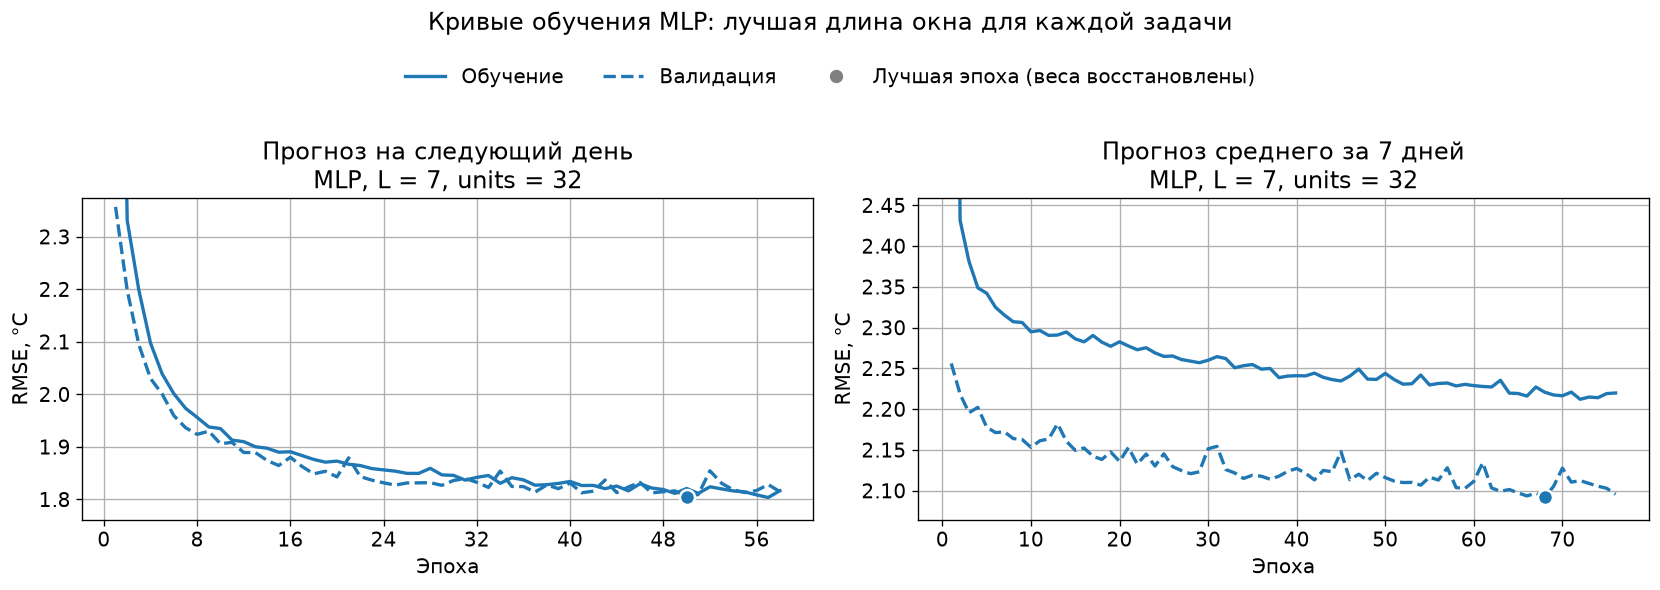

In [ ]:
# Кривые обучения лучшей по валидации конфигурации MLP для обеих задач
plot_architecture_curves("MLP")

**Результат:** для следующего дня лучшая длина окна - 7 дней: RMSE 1,8050 °C, R2 0,9296. Худший результат при L = 60: RMSE 1,9972 °C. Для недельного среднего лучший результат при L = 7: RMSE 2,0917 °C, R2 0,8973; худший при L = 30: RMSE 2,2594 °C. MLP не использует порядок значений, поэтому длинная история для него - это просто много шумных признаков.

### 2. SimpleRNN: влияние длины окна

SimpleRNN обрабатывает окно по шагам и хранит скрытое состояние. На длинных окнах ожидается затухание градиента, поэтому качество может перестать расти.

In [22]:
# Этап 1, SimpleRNN: 32 ячейки, перебираем длины окна
for task in TASKS:
    for window in WINDOW_LENGTHS:
        record = run_experiment(task, "SimpleRNN", window, units=32)
        print(
            task, "L =", window,
            "val RMSE =", round(record["val_RMSE"], 4),
            "val R2 =", round(record["val_R2"], 4),
        )

rnn_stage = runs_frame()
rnn_stage = rnn_stage[(rnn_stage["model"] == "SimpleRNN") & (rnn_stage["units"] == 32)]
display(rnn_stage.sort_values(["task", "window"]).reset_index(drop=True))

next_day L = 7 val RMSE = 1.7863 val R2 = 0.9311


next_day L = 14 val RMSE = 1.7869 val R2 = 0.931


next_day L = 30 val RMSE = 1.8153 val R2 = 0.9288


next_day L = 60 val RMSE = 1.7934 val R2 = 0.9305


weekly_mean L = 7 val RMSE = 2.0937 val R2 = 0.8971


weekly_mean L = 14 val RMSE = 2.0718 val R2 = 0.8992


weekly_mean L = 30 val RMSE = 2.1649 val R2 = 0.8899


weekly_mean L = 60 val RMSE = 1.9804 val R2 = 0.9079


,run_id,task,model,window,units,optimizer,dropout,params,epochs_run,best_epoch,train_time_s,val_MAE,val_MSE,val_RMSE,val_R2
0,8,next_day,SimpleRNN,7,32,adam,0.0,1121,15,7,23.44,1.2794,3.1908,1.7863,0.9311
1,9,next_day,SimpleRNN,14,32,adam,0.0,1121,23,15,50.42,1.2838,3.1930,1.7869,0.9310
2,10,next_day,SimpleRNN,30,32,adam,0.0,1121,16,8,55.53,1.3083,3.2955,1.8153,0.9288
3,11,next_day,SimpleRNN,60,32,adam,0.0,1121,20,12,120.46,1.2791,3.2162,1.7934,0.9305
4,12,weekly_mean,SimpleRNN,7,32,adam,0.0,1121,17,9,26.29,1.6678,4.3837,2.0937,0.8971
5,13,weekly_mean,SimpleRNN,14,32,adam,0.0,1121,24,16,53.11,1.6738,4.2924,2.0718,0.8992
6,14,weekly_mean,SimpleRNN,30,32,adam,0.0,1121,15,7,54.28,1.7168,4.6866,2.1649,0.8899
7,15,weekly_mean,SimpleRNN,60,32,adam,0.0,1121,14,6,86.36,1.6165,3.9220,1.9804,0.9079


#### Кривые обучения SimpleRNN

Для каждой задачи показана лучшая по валидации конфигурация SimpleRNN из этого эксперимента. По кривым видно, за сколько эпох модель выходит на плато и растет ли ошибка на валидации, пока ошибка на обучении падает, то есть появляется ли переобучение.

прогноз на следующий день, SimpleRNN, L = 7, units = 32: лучшая эпоха 7 из 15 , val RMSE = 1.7863 °C
прогноз среднего за 7 дней, SimpleRNN, L = 60, units = 32: лучшая эпоха 10 из 18 , val RMSE = 2.0126 °C


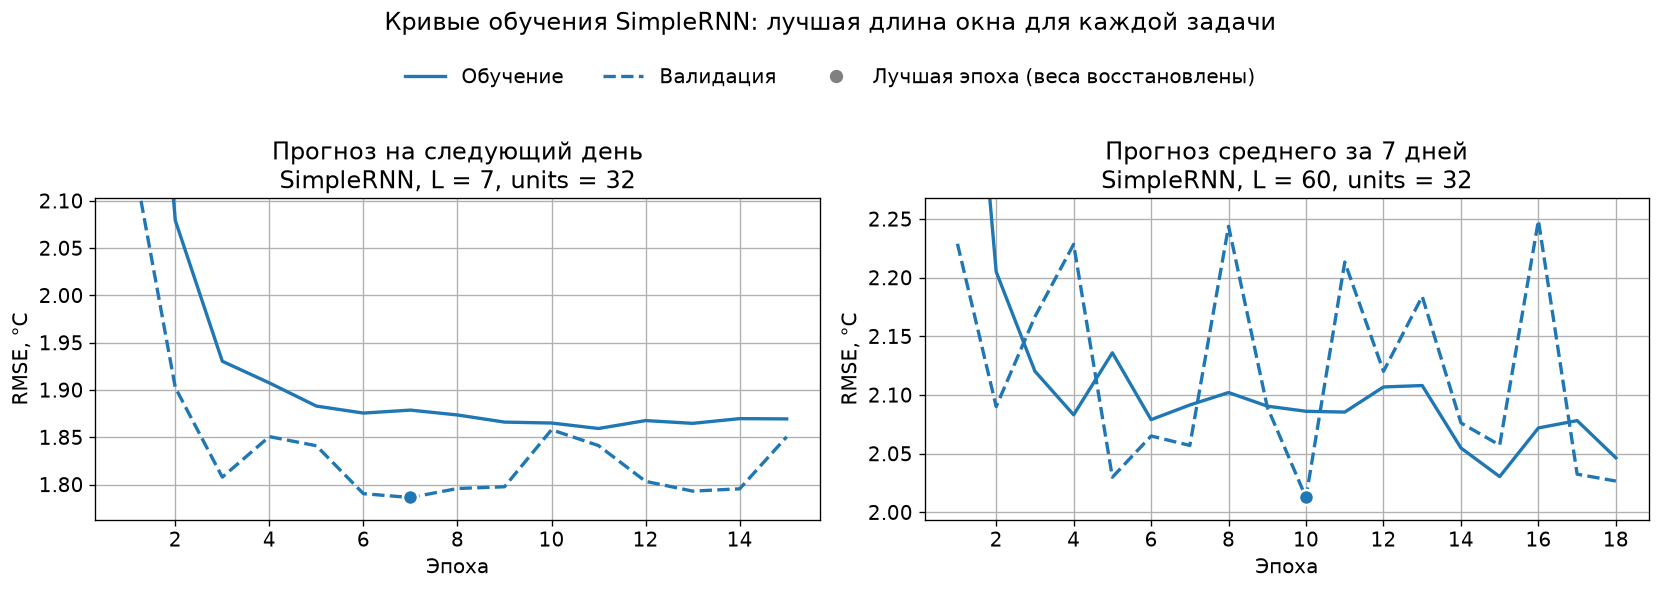

In [ ]:
# Кривые обучения лучшей по валидации конфигурации SimpleRNN для обеих задач
plot_architecture_curves("SimpleRNN")

**Результат:** SimpleRNN для следующего дня почти не зависит от длины окна: RMSE меняется от 1,7863 до 1,8153 °C, лучшее значение при L = 7 (R2 0,9311). Для недельного среднего длинное окно помогает: лучшее значение при L = 60, RMSE 1,9804 °C и R2 0,9079 против 2,0937 °C при L = 7. Для недельного горизонта нужен более длинный контекст, но затухание градиента не позволяет выигрывать дальше.

### 3. LSTM: влияние длины окна

LSTM использует ворота и отдельную ячейку памяти, поэтому лучше сохраняет долгосрочную информацию. Здесь проверяется, дает ли это преимущество на окнах до 60 дней.

In [24]:
# Этап 1, LSTM: 32 ячейки, перебираем длины окна
for task in TASKS:
    for window in WINDOW_LENGTHS:
        record = run_experiment(task, "LSTM", window, units=32)
        print(
            task, "L =", window,
            "val RMSE =", round(record["val_RMSE"], 4),
            "val R2 =", round(record["val_R2"], 4),
        )

lstm_stage = runs_frame()
lstm_stage = lstm_stage[(lstm_stage["model"] == "LSTM") & (lstm_stage["units"] == 32)]
display(lstm_stage.sort_values(["task", "window"]).reset_index(drop=True))

next_day L = 7 val RMSE = 1.7929 val R2 = 0.9306


next_day L = 14 val RMSE = 1.7911 val R2 = 0.9307


next_day L = 30 val RMSE = 1.7928 val R2 = 0.9306


next_day L = 60 val RMSE = 1.7814 val R2 = 0.9315


weekly_mean L = 7 val RMSE = 2.0894 val R2 = 0.8975


weekly_mean L = 14 val RMSE = 2.0703 val R2 = 0.8994


weekly_mean L = 30 val RMSE = 2.1821 val R2 = 0.8882


weekly_mean L = 60 val RMSE = 1.8937 val R2 = 0.9158


,run_id,task,model,window,units,optimizer,dropout,params,epochs_run,best_epoch,train_time_s,val_MAE,val_MSE,val_RMSE,val_R2
0,16,next_day,LSTM,7,32,adam,0.0,4385,45,37,43.90,1.2859,3.2146,1.7929,0.9306
1,17,next_day,LSTM,14,32,adam,0.0,4385,35,27,34.54,1.2823,3.2080,1.7911,0.9307
2,18,next_day,LSTM,30,32,adam,0.0,4385,36,28,35.96,1.2885,3.2142,1.7928,0.9306
3,19,next_day,LSTM,60,32,adam,0.0,4385,44,36,43.84,1.2732,3.1733,1.7814,0.9315
4,20,weekly_mean,LSTM,7,32,adam,0.0,4385,45,37,44.81,1.6831,4.3654,2.0894,0.8975
5,21,weekly_mean,LSTM,14,32,adam,0.0,4385,39,31,39.42,1.6667,4.2860,2.0703,0.8994
6,22,weekly_mean,LSTM,30,32,adam,0.0,4385,16,8,16.13,1.7366,4.7615,2.1821,0.8882
7,23,weekly_mean,LSTM,60,32,adam,0.0,4385,31,23,30.48,1.4849,3.5862,1.8937,0.9158


#### Кривые обучения LSTM

Для каждой задачи показана лучшая по валидации конфигурация LSTM из этого эксперимента. По кривым видно, за сколько эпох модель выходит на плато и растет ли ошибка на валидации, пока ошибка на обучении падает, то есть появляется ли переобучение.

прогноз на следующий день, LSTM, L = 60, units = 32: лучшая эпоха 36 из 44 , val RMSE = 1.7819 °C
прогноз среднего за 7 дней, LSTM, L = 60, units = 32: лучшая эпоха 23 из 31 , val RMSE = 1.8937 °C


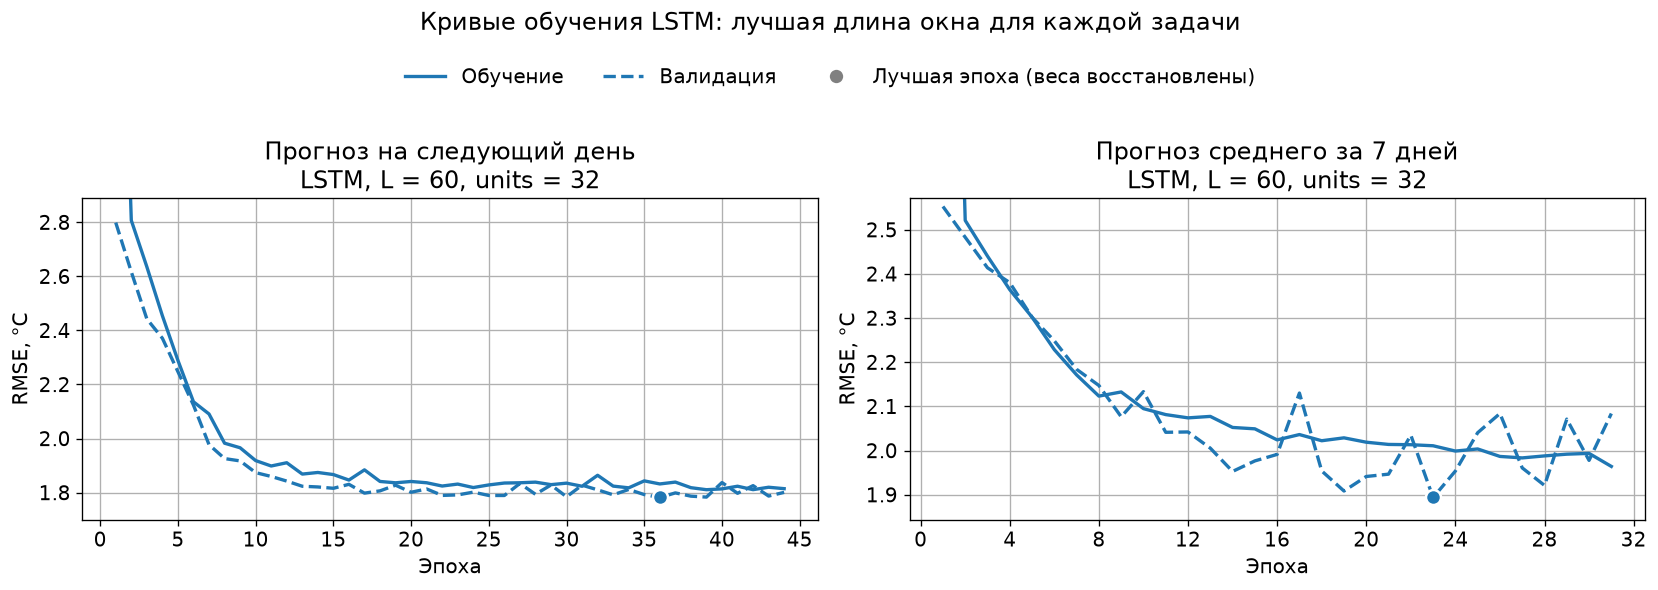

In [ ]:
# Кривые обучения лучшей по валидации конфигурации LSTM для обеих задач
plot_architecture_curves("LSTM")

**Результат:** LSTM для следующего дня дает RMSE от 1,7814 до 1,7929 °C во всем диапазоне окон, лучшее значение при L = 60 (R2 0,9315). Для недельного среднего выигрыш длинного окна выражен сильнее: лучшее значение при L = 60, RMSE 1,8937 °C и R2 0,9158; худшее при L = 30: RMSE 2,1821 °C. LSTM лучше остальных использует длинную историю.

### 4. Stacked LSTM: влияние длины окна

Два последовательных слоя LSTM увеличивают глубину и число параметров. Первый слой возвращает последовательность, второй формирует итоговое представление.

In [26]:
# Этап 1, Stacked LSTM: два слоя по 32 ячейки, перебираем длины окна
for task in TASKS:
    for window in WINDOW_LENGTHS:
        record = run_experiment(task, "StackedLSTM", window, units=32)
        print(
            task, "L =", window,
            "val RMSE =", round(record["val_RMSE"], 4),
            "val R2 =", round(record["val_R2"], 4),
        )

stacked_stage = runs_frame()
stacked_stage = stacked_stage[(stacked_stage["model"] == "StackedLSTM") & (stacked_stage["units"] == 32)]
display(stacked_stage.sort_values(["task", "window"]).reset_index(drop=True))

next_day L = 7 val RMSE = 1.7868 val R2 = 0.931


next_day L = 14 val RMSE = 1.793 val R2 = 0.9306


next_day L = 30 val RMSE = 1.7951 val R2 = 0.9304


next_day L = 60 val RMSE = 1.7925 val R2 = 0.9306


weekly_mean L = 7 val RMSE = 2.0876 val R2 = 0.8977


weekly_mean L = 14 val RMSE = 2.0744 val R2 = 0.8989


weekly_mean L = 30 val RMSE = 2.2578 val R2 = 0.8803


weekly_mean L = 60 val RMSE = 2.0892 val R2 = 0.8975


,run_id,task,model,window,units,optimizer,dropout,params,epochs_run,best_epoch,train_time_s,val_MAE,val_MSE,val_RMSE,val_R2
0,24,next_day,StackedLSTM,7,32,adam,0.0,12705,34,26,40.87,1.2862,3.1927,1.7868,0.9310
1,25,next_day,StackedLSTM,14,32,adam,0.0,12705,22,14,26.15,1.2899,3.2149,1.7930,0.9306
2,26,next_day,StackedLSTM,30,32,adam,0.0,12705,23,15,27.15,1.2873,3.2224,1.7951,0.9304
3,27,next_day,StackedLSTM,60,32,adam,0.0,12705,25,17,29.97,1.2713,3.2130,1.7925,0.9306
4,28,weekly_mean,StackedLSTM,7,32,adam,0.0,12705,24,16,28.44,1.6856,4.3579,2.0876,0.8977
5,29,weekly_mean,StackedLSTM,14,32,adam,0.0,12705,32,24,38.79,1.6662,4.3033,2.0744,0.8989
6,30,weekly_mean,StackedLSTM,30,32,adam,0.0,12705,15,7,18.02,1.8195,5.0979,2.2578,0.8803
7,31,weekly_mean,StackedLSTM,60,32,adam,0.0,12705,26,18,31.16,1.7266,4.3649,2.0892,0.8975


#### Кривые обучения Stacked LSTM

Для каждой задачи показана лучшая по валидации конфигурация Stacked LSTM из этого эксперимента. По кривым видно, за сколько эпох модель выходит на плато и растет ли ошибка на валидации, пока ошибка на обучении падает, то есть появляется ли переобучение.

прогноз на следующий день, Stacked LSTM, L = 7, units = 32: лучшая эпоха 26 из 34 , val RMSE = 1.7868 °C
прогноз среднего за 7 дней, Stacked LSTM, L = 14, units = 32: лучшая эпоха 24 из 32 , val RMSE = 2.0744 °C


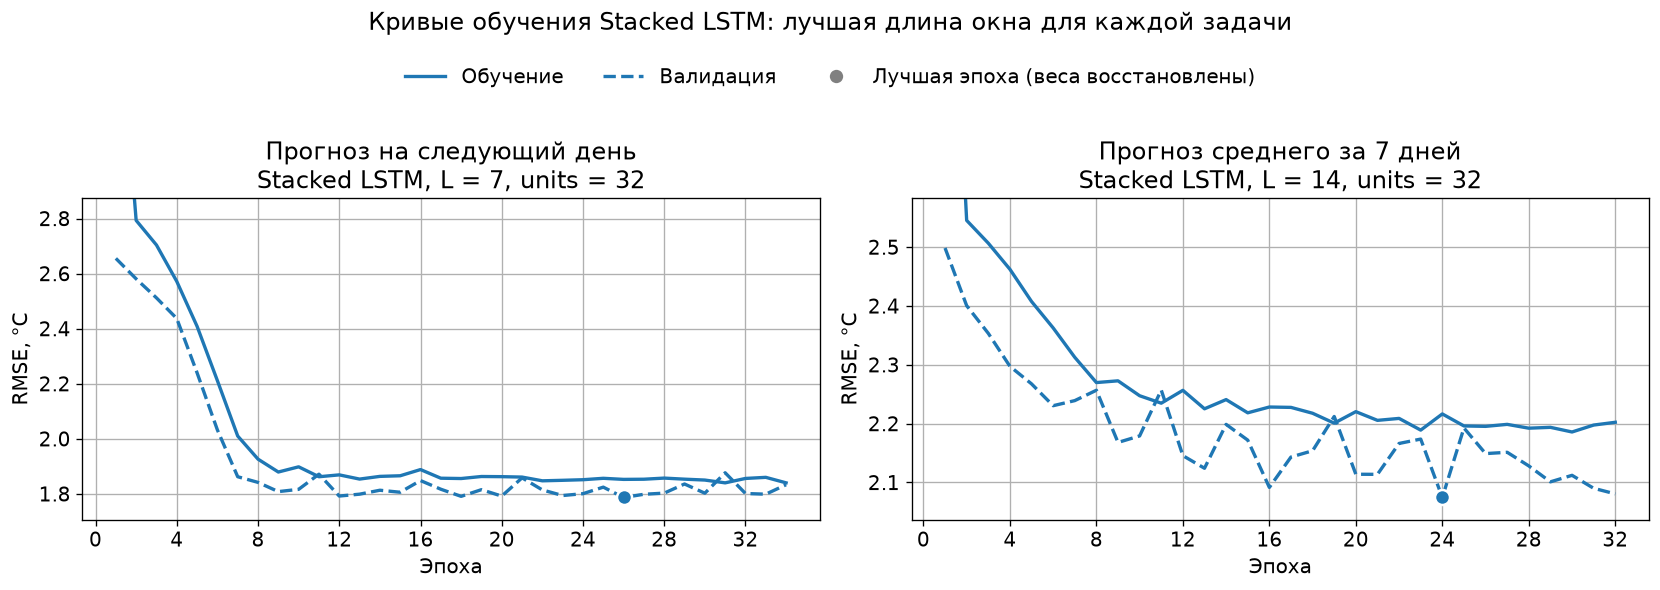

In [ ]:
# Кривые обучения лучшей по валидации конфигурации Stacked LSTM для обеих задач
plot_architecture_curves("StackedLSTM")

**Результат:** двухслойная LSTM для следующего дня показывает RMSE от 1,7868 до 1,7951 °C, лучший результат при L = 7 (R2 0,9310). Для недельного среднего лучшее значение при L = 14: RMSE 2,0744 °C, R2 0,8989; худшее при L = 30: RMSE 2,2578 °C. Второй рекуррентный слой не дал устойчивого выигрыша по сравнению с однослойной LSTM и увеличил число параметров до 12 705.

### 5. Влияние числа нейронов и ячеек

Для каждой архитектуры и каждой задачи выбирается лучшая длина окна по validation RMSE, затем та же конфигурация обучается с 64 нейронами или ячейками. Сравнение показывает, дает ли увеличение емкости выигрыш или приводит к переобучению.

In [28]:
# Этап 2: для лучшей длины окна увеличиваем число нейронов до 64
stage1 = runs_frame()
stage1 = stage1[stage1["units"] == 32]
best_window = (
    stage1.sort_values("val_RMSE")
    .groupby(["task", "model"], as_index=False)
    .head(1)[["task", "model", "window", "units", "val_RMSE"]]
)
display(best_window.sort_values(["task", "model"]).reset_index(drop=True))

for _, row in best_window.iterrows():
    record = run_experiment(
        row["task"],
        row["model"],
        int(row["window"]),
        units=64,
    )
    print(
        row["task"], row["model"], "L =", int(row["window"]),
        "units = 64, val RMSE =", round(record["val_RMSE"], 4),
    )

units_stage = runs_frame()
units_stage = units_stage[units_stage["units"] == 64]
display(units_stage.sort_values(["task", "val_RMSE"]).reset_index(drop=True))

,task,model,window,units,val_RMSE
0,next_day,LSTM,60,32,1.7814
1,next_day,MLP,7,32,1.8050
2,next_day,SimpleRNN,7,32,1.7863
3,next_day,StackedLSTM,7,32,1.7868
4,weekly_mean,LSTM,60,32,1.8937
5,weekly_mean,MLP,7,32,2.0917
6,weekly_mean,SimpleRNN,60,32,1.9804
7,weekly_mean,StackedLSTM,14,32,2.0744


next_day LSTM L = 60 units = 64, val RMSE = 1.7959


next_day SimpleRNN L = 7 units = 64, val RMSE = 1.7934


next_day StackedLSTM L = 7 units = 64, val RMSE = 1.7916


next_day MLP L = 7 units = 64, val RMSE = 1.7567


weekly_mean LSTM L = 60 units = 64, val RMSE = 2.0008


weekly_mean SimpleRNN L = 60 units = 64, val RMSE = 2.0369


weekly_mean StackedLSTM L = 14 units = 64, val RMSE = 2.0879


weekly_mean MLP L = 7 units = 64, val RMSE = 2.1022


,run_id,task,model,window,units,optimizer,dropout,params,epochs_run,best_epoch,train_time_s,val_MAE,val_MSE,val_RMSE,val_R2
0,35,next_day,MLP,7,64,adam,0.0,577,38,30,30.39,1.2570,3.0862,1.7567,0.9333
1,34,next_day,StackedLSTM,7,64,adam,0.0,49985,23,15,27.68,1.2853,3.2097,1.7916,0.9307
2,33,next_day,SimpleRNN,7,64,adam,0.0,4289,14,6,21.79,1.2817,3.2164,1.7934,0.9305
3,32,next_day,LSTM,60,64,adam,0.0,16961,25,17,24.63,1.2727,3.2251,1.7959,0.9303
4,36,weekly_mean,LSTM,60,64,adam,0.0,16961,26,18,24.98,1.6265,4.0032,2.0008,0.9060
5,37,weekly_mean,SimpleRNN,60,64,adam,0.0,4289,18,10,109.85,1.6365,4.1488,2.0369,0.9026
6,38,weekly_mean,StackedLSTM,14,64,adam,0.0,49985,24,16,28.65,1.6743,4.3594,2.0879,0.8976
7,39,weekly_mean,MLP,7,64,adam,0.0,577,36,28,28.73,1.6970,4.4191,2.1022,0.8962


#### Кривые обучения: число нейронов

Для каждой задачи - четыре панели, по одной на архитектуру. Синий - лучшая конфигурация с 32 нейронами или ячейками, оранжевый - та же конфигурация с 64. Если у варианта с 64 ошибка на обучении ниже, а на валидации выше, лишняя емкость ведет к переобучению.

MLP, L = 7, 32: лучшая эпоха 50 из 58 , val RMSE = 1.805 °C
MLP, L = 7, 64: лучшая эпоха 30 из 38 , val RMSE = 1.7567 °C
SimpleRNN, L = 7, 32: лучшая эпоха 7 из 15 , val RMSE = 1.7863 °C
SimpleRNN, L = 7, 64: лучшая эпоха 6 из 14 , val RMSE = 1.7934 °C
LSTM, L = 60, 32: лучшая эпоха 36 из 44 , val RMSE = 1.7819 °C
LSTM, L = 60, 64: лучшая эпоха 17 из 25 , val RMSE = 1.7959 °C
Stacked LSTM, L = 7, 32: лучшая эпоха 26 из 34 , val RMSE = 1.7868 °C
Stacked LSTM, L = 7, 64: лучшая эпоха 15 из 23 , val RMSE = 1.7916 °C


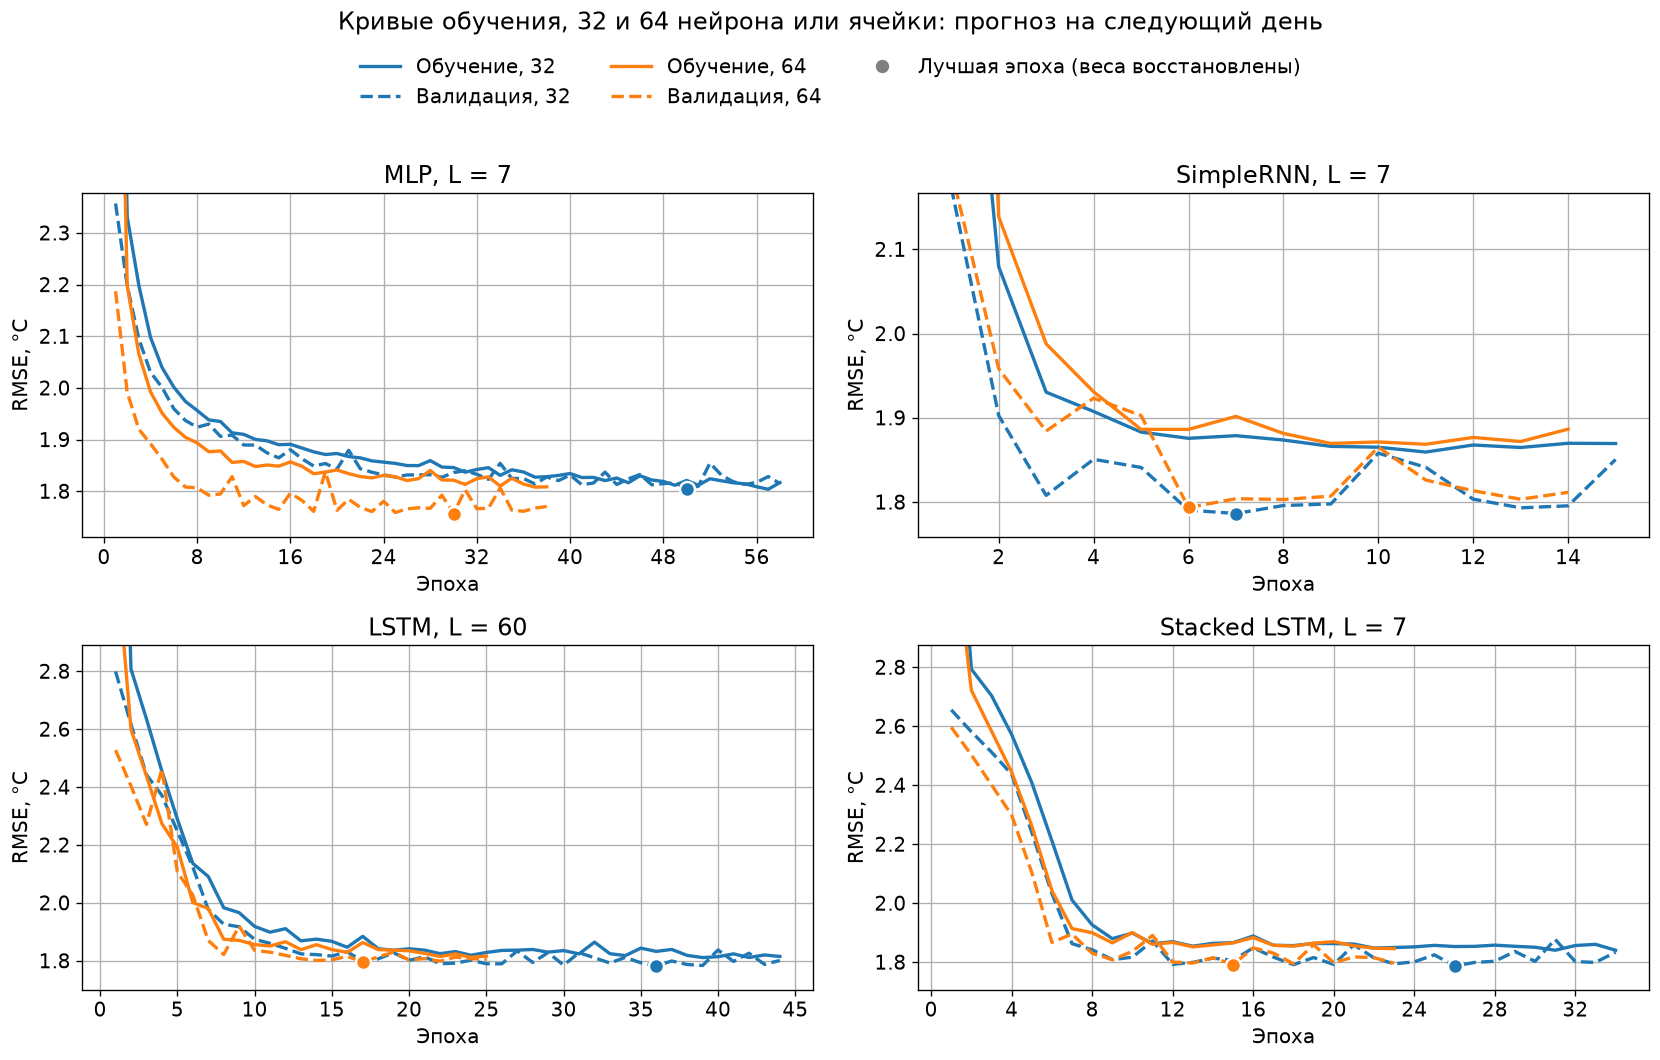

MLP, L = 7, 32: лучшая эпоха 68 из 76 , val RMSE = 2.0917 °C
MLP, L = 7, 64: лучшая эпоха 28 из 36 , val RMSE = 2.1022 °C
SimpleRNN, L = 60, 32: лучшая эпоха 10 из 18 , val RMSE = 2.0126 °C
SimpleRNN, L = 60, 64: лучшая эпоха 4 из 12 , val RMSE = 2.0385 °C
LSTM, L = 60, 32: лучшая эпоха 23 из 31 , val RMSE = 1.8937 °C
LSTM, L = 60, 64: лучшая эпоха 18 из 26 , val RMSE = 2.0008 °C
Stacked LSTM, L = 14, 32: лучшая эпоха 24 из 32 , val RMSE = 2.0744 °C
Stacked LSTM, L = 14, 64: лучшая эпоха 16 из 24 , val RMSE = 2.0879 °C


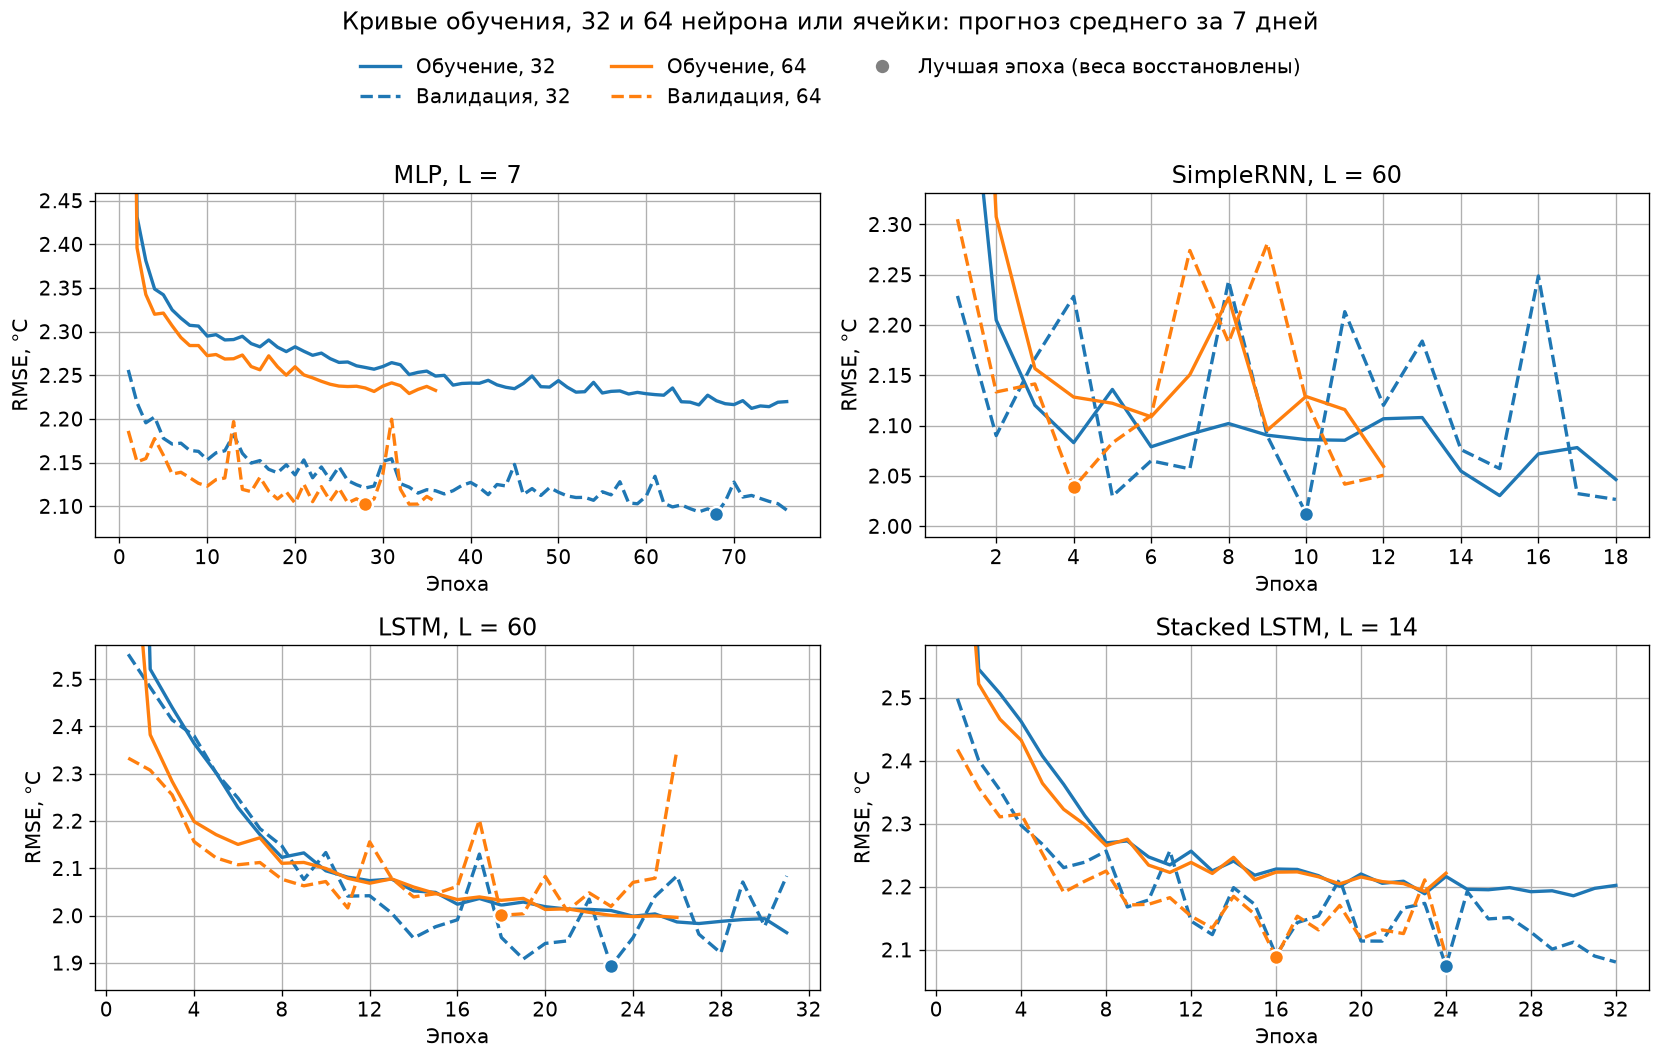

In [ ]:
# Кривые обучения: конфигурация с 32 нейронами и та же с 64, по задачам
all_runs = runs_frame()

for task in TASKS:
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    for axis, model_type in zip(axes.ravel(), MODEL_TITLES):
        # Вариант с 64: окно уже выбрано по валидации на этапе с 32
        new_record = all_runs[
            (all_runs["task"] == task) & (all_runs["model"] == model_type)
            & (all_runs["units"] == 64) & (all_runs["optimizer"] == "adam")
            & (all_runs["dropout"] == 0)
        ].iloc[0]
        # Исходный вариант: те же задача, модель и окно, но 32 нейрона
        base_record = all_runs[
            (all_runs["task"] == task) & (all_runs["model"] == model_type)
            & (all_runs["window"] == new_record["window"]) & (all_runs["units"] == 32)
            & (all_runs["optimizer"] == "adam") & (all_runs["dropout"] == 0)
        ].iloc[0]
        plot_pair_curves(axis, base_record, new_record, "32", "64",
                         MODEL_TITLES[model_type] + ", L = " + str(int(new_record["window"])))
    fig.suptitle("Кривые обучения, 32 и 64 нейрона или ячейки: " + TASK_TITLES[task])
    fig.tight_layout(rect=[0, 0, 1, add_figure_legend(fig, axes.ravel()[0])])
    fig.savefig(FIGURES_DIR / ("lab2-curves-units-" + task + ".png"), bbox_inches="tight")
    plt.show()

**Результат:** увеличение до 64 нейронов помогло MLP в задаче на следующий день: RMSE 1,8050 -> 1,7567 °C. У остальных конфигураций рост емкости ухудшил validation RMSE, например: SimpleRNN в задаче на следующий день: 1,7863 -> 1,7934 °C; LSTM в задаче на следующий день: 1,7814 -> 1,7959 °C; Stacked LSTM в задаче на следующий день: 1,7868 -> 1,7916 °C; MLP в задаче на недельное среднее: 2,0917 -> 2,1022 °C. В задаче на следующий день и у MLP и Stacked LSTM на недельном среднем разница составляет 0,005-0,015 °C - это не больше разброса между запусками (раздел 9), то есть удвоение емкости ничего не дает. У LSTM и SimpleRNN на недельном среднем 64 ячейки заметно хуже (на 0,1071 и 0,0565 °C): модель с большим числом параметров быстрее подстраивается под обучающий период, и ошибка на валидации раньше перестает снижаться. Поэтому, кроме MLP на следующий день, оставлены 32 нейрона или ячейки.

### 6. Сравнение оптимизаторов

Для лучшей конфигурации каждой задачи, выбранной по validation, обучение повторяется с RMSprop. Остальные параметры не меняются, чтобы разница отражала только оптимизатор.

In [30]:
# Этап 3: проверяем RMSprop вместо Adam для лучших конфигураций
current = runs_frame()
best_config = (
    current.sort_values("val_RMSE")
    .groupby("task", as_index=False)
    .head(1)[["task", "model", "window", "units", "optimizer", "dropout", "val_RMSE"]]
)
display(best_config.reset_index(drop=True))

for _, row in best_config.iterrows():
    if row["optimizer"] == "rmsprop":
        print(row["task"], "лучшая конфигурация уже использует RMSprop, повтор не нужен")
        continue
    record = run_experiment(
        row["task"],
        row["model"],
        int(row["window"]),
        int(row["units"]),
        optimizer_name="rmsprop",
        dropout=float(row["dropout"]),
    )
    print(
        row["task"], row["model"], "L =", int(row["window"]),
        "units =", int(row["units"]), "RMSprop, val RMSE =", round(record["val_RMSE"], 4),
    )

optimizer_stage = runs_frame()
optimizer_stage = optimizer_stage[
    (optimizer_stage["window"].isin(best_config["window"]))
    & (optimizer_stage["units"].isin(best_config["units"]))
]
display(optimizer_stage.sort_values(["task", "optimizer"]).reset_index(drop=True))

,task,model,window,units,optimizer,dropout,val_RMSE
0,next_day,MLP,7,64,adam,0.0,1.7567
1,weekly_mean,LSTM,60,32,adam,0.0,1.8937


next_day MLP L = 7 units = 64 RMSprop, val RMSE = 1.7601


weekly_mean LSTM L = 60 units = 32 RMSprop, val RMSE = 1.9293


,run_id,task,model,window,units,optimizer,dropout,params,epochs_run,best_epoch,train_time_s,val_MAE,val_MSE,val_RMSE,val_R2
0,0,next_day,MLP,7,32,adam,0.0,289,58,50,43.32,1.2928,3.2579,1.8050,0.9296
1,3,next_day,MLP,60,32,adam,0.0,1985,53,45,41.98,1.4503,3.9887,1.9972,0.9139
2,8,next_day,SimpleRNN,7,32,adam,0.0,1121,15,7,23.44,1.2794,3.1908,1.7863,0.9311
3,11,next_day,SimpleRNN,60,32,adam,0.0,1121,20,12,120.46,1.2791,3.2162,1.7934,0.9305
4,16,next_day,LSTM,7,32,adam,0.0,4385,45,37,43.90,1.2859,3.2146,1.7929,0.9306
5,19,next_day,LSTM,60,32,adam,0.0,4385,44,36,43.84,1.2732,3.1733,1.7814,0.9315
6,24,next_day,StackedLSTM,7,32,adam,0.0,12705,34,26,40.87,1.2862,3.1927,1.7868,0.9310
7,27,next_day,StackedLSTM,60,32,adam,0.0,12705,25,17,29.97,1.2713,3.2130,1.7925,0.9306
8,32,next_day,LSTM,60,64,adam,0.0,16961,25,17,24.63,1.2727,3.2251,1.7959,0.9303
9,33,next_day,SimpleRNN,7,64,adam,0.0,4289,14,6,21.79,1.2817,3.2164,1.7934,0.9305


#### Кривые обучения: оптимизаторы

Для лучшей конфигурации каждой задачи на одних осях показаны Adam (синий) и RMSprop (оранжевый). По кривым видно, какой оптимизатор быстрее снижает ошибку и насколько устойчиво ведет себя ошибка на валидации.

Прогноз на следующий день, MLP, L = 7, units = 64, Adam: лучшая эпоха 30 из 38 , val RMSE = 1.7567 °C
Прогноз на следующий день, MLP, L = 7, units = 64, RMSprop: лучшая эпоха 21 из 29 , val RMSE = 1.7601 °C
Прогноз среднего за 7 дней, LSTM, L = 60, units = 32, Adam: лучшая эпоха 23 из 31 , val RMSE = 1.8937 °C
Прогноз среднего за 7 дней, LSTM, L = 60, units = 32, RMSprop: лучшая эпоха 19 из 27 , val RMSE = 1.9293 °C


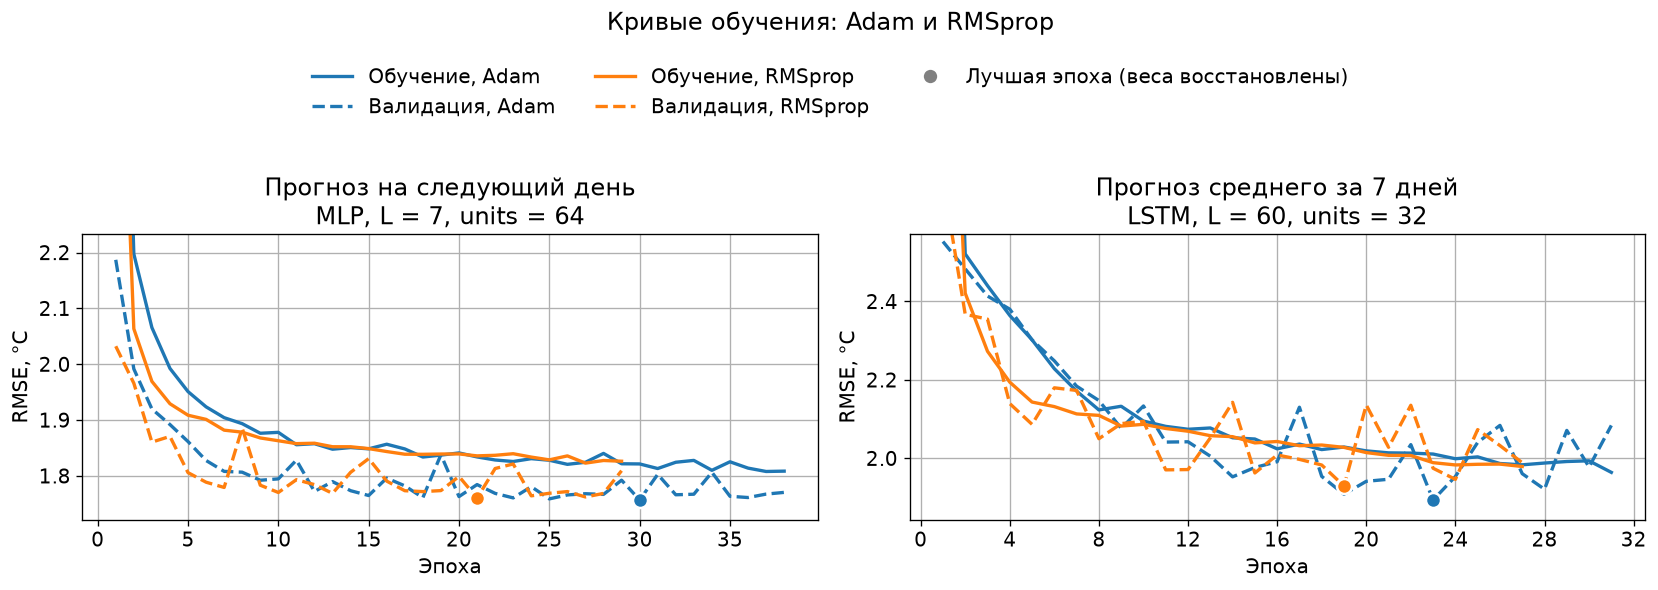

In [ ]:
# Кривые обучения: Adam и RMSprop для лучшей конфигурации каждой задачи
all_runs = runs_frame()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for axis, (_, row) in zip(axes, best_config.iterrows()):
    # Остальные параметры совпадают, отличается только оптимизатор
    same_config = (
        (all_runs["task"] == row["task"])
        & (all_runs["model"] == row["model"])
        & (all_runs["window"] == row["window"])
        & (all_runs["units"] == row["units"])
        & (all_runs["dropout"] == row["dropout"])
    )
    adam_run = all_runs[same_config & (all_runs["optimizer"] == "adam")].iloc[0]
    rmsprop_run = all_runs[same_config & (all_runs["optimizer"] == "rmsprop")].iloc[0]
    plot_pair_curves(axis, adam_run, rmsprop_run, "Adam", "RMSprop",
                     TASK_TITLES[row["task"]].capitalize() + "\n" + config_text(adam_run))

fig.suptitle("Кривые обучения: Adam и RMSprop")
fig.tight_layout(rect=[0, 0, 1, add_figure_legend(fig, axes[0])])
fig.savefig(FIGURES_DIR / "lab2-curves-optimizer.png", bbox_inches="tight")
plt.show()

**Результат:** Adam оказался лучше RMSprop в обеих задачах: MLP на следующий день - RMSE 1,7567 против 1,7601 °C; LSTM на недельное среднее - RMSE 1,8937 против 1,9293 °C. Разница небольшая, но при одинаковых остальных параметрах Adam стабильнее, поэтому он оставлен основным оптимизатором.

### 7. Эксперимент с Dropout

Dropout добавляется после рекуррентного слоя или после Dense-слоя в MLP. Сначала модель обучалась без регуляризации, поэтому по кривым обучения видно, было ли переобучение. Этот эксперимент проверяет, помогает ли Dropout 0,2 лучшей конфигурации каждой задачи.

In [32]:
# Этап 4: проверяем Dropout 0.2 для лучших конфигураций
current = runs_frame()
best_config = (
    current.sort_values("val_RMSE")
    .groupby("task", as_index=False)
    .head(1)[["task", "model", "window", "units", "optimizer", "dropout", "val_RMSE"]]
)

for _, row in best_config.iterrows():
    record = run_experiment(
        row["task"],
        row["model"],
        int(row["window"]),
        int(row["units"]),
        optimizer_name=row["optimizer"],
        dropout=0.2,
    )
    print(
        row["task"], row["model"], "L =", int(row["window"]),
        "units =", int(row["units"]), "Dropout = 0.2, val RMSE =", round(record["val_RMSE"], 4),
    )

dropout_stage = runs_frame()
dropout_stage = dropout_stage[dropout_stage["dropout"] > 0]
display(dropout_stage.sort_values(["task", "val_RMSE"]).reset_index(drop=True))

next_day MLP L = 7 units = 64 Dropout = 0.2, val RMSE = 1.7766


weekly_mean LSTM L = 60 units = 32 Dropout = 0.2, val RMSE = 2.0129


,run_id,task,model,window,units,optimizer,dropout,params,epochs_run,best_epoch,train_time_s,val_MAE,val_MSE,val_RMSE,val_R2
0,42,next_day,MLP,7,64,adam,0.2,577,31,23,23.82,1.2873,3.1564,1.7766,0.9318
1,43,weekly_mean,LSTM,60,32,adam,0.2,4385,27,19,25.47,1.6334,4.0518,2.0129,0.9049


In [33]:
# Сохраняем все прогоны, чтобы числа в отчете можно было проверить
runs_frame().to_csv(RESULTS_DIR / "lab2-runs.csv", index=False, encoding="utf-8")
print("Сохранено прогонов:", len(runs))

Сохранено прогонов: 44


**Результат:** Dropout 0,2 ухудшил validation RMSE в обеих задачах: MLP на следующий день - 1,7567 -> 1,7766 °C; LSTM на недельное среднее - 1,8937 -> 2,0129 °C. С EarlyStopping переобучение не успевает развиться: обучение останавливается через 8 эпох после минимума ошибки на валидации, и веса возвращаются к лучшей эпохе (без EarlyStopping переобучение есть, см. раздел 8). Dropout поверх этого ничего не добавил: у LSTM на недельном среднем ухудшение (0,1192 °C) намного больше разброса между запусками (раздел 9). Поэтому в итоговых моделях Dropout не используется.

#### Кривые обучения до и после Dropout

Лучшая конфигурация каждой задачи без регуляризации (синий) и та же конфигурация с Dropout 0,2 (оранжевый). Dropout помогает, только если без него ошибка на валидации заметно выше, чем на обучении, и растет.

Прогноз на следующий день, MLP, L = 7, units = 64, без Dropout: лучшая эпоха 30 из 38 , val RMSE = 1.7567 °C
Прогноз на следующий день, MLP, L = 7, units = 64, Dropout 0,2: лучшая эпоха 23 из 31 , val RMSE = 1.7766 °C
Прогноз среднего за 7 дней, LSTM, L = 60, units = 32, без Dropout: лучшая эпоха 23 из 31 , val RMSE = 1.8937 °C
Прогноз среднего за 7 дней, LSTM, L = 60, units = 32, Dropout 0,2: лучшая эпоха 19 из 27 , val RMSE = 2.0129 °C


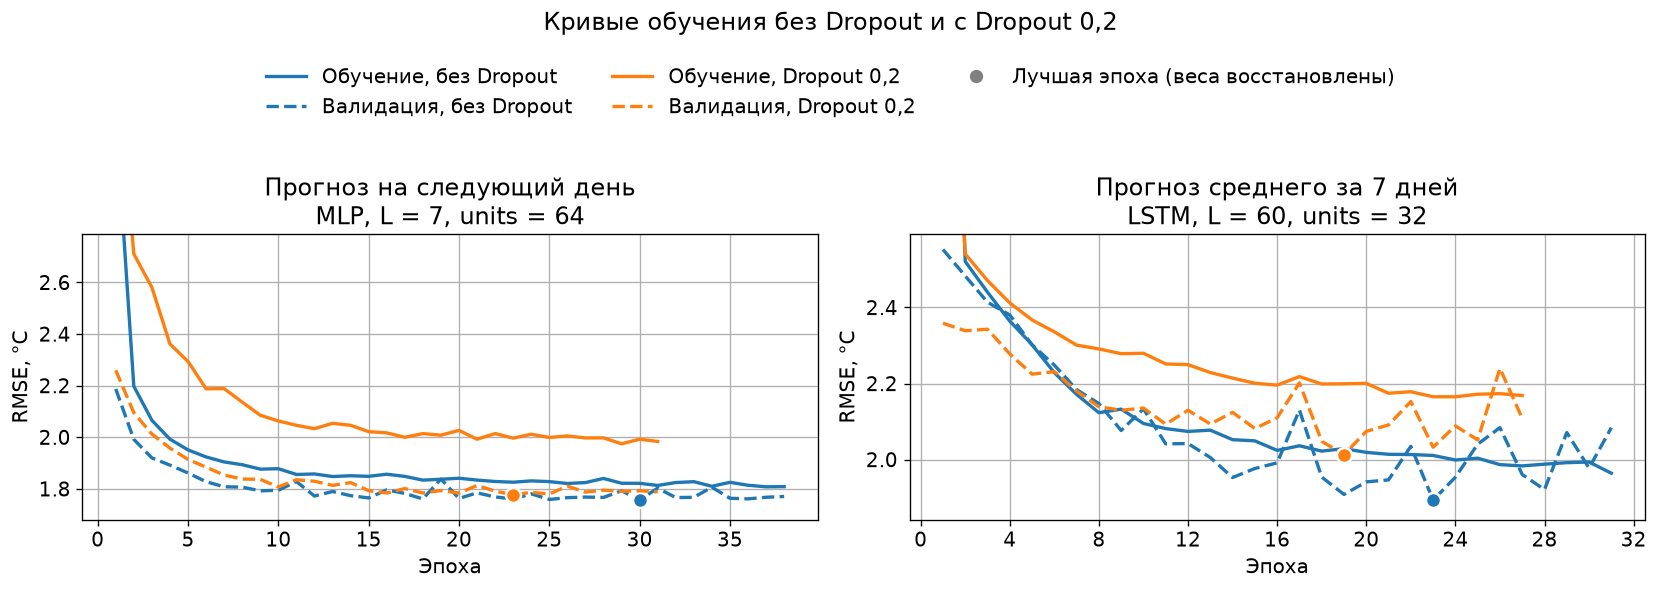

In [ ]:
# Сравнение кривых обучения без Dropout и с Dropout 0.2
all_runs = runs_frame()
dropout_runs = all_runs[all_runs["dropout"] > 0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for axis, task in zip(axes, TASKS):
    drop = dropout_runs[dropout_runs["task"] == task].iloc[0]
    base = all_runs[
        (all_runs["task"] == task)
        & (all_runs["model"] == drop["model"])
        & (all_runs["window"] == drop["window"])
        & (all_runs["units"] == drop["units"])
        & (all_runs["optimizer"] == drop["optimizer"])
        & (all_runs["dropout"] == 0)
    ].iloc[0]
    plot_pair_curves(axis, base, drop, "без Dropout", "Dropout 0,2",
                     TASK_TITLES[task].capitalize() + "\n" + config_text(base))

fig.suptitle("Кривые обучения без Dropout и с Dropout 0,2")
fig.tight_layout(rect=[0, 0, 1, add_figure_legend(fig, axes[0])])
fig.savefig(FIGURES_DIR / "lab2-curves-dropout.png", bbox_inches="tight")
plt.show()

### 8. Обучение без EarlyStopping

Все прогоны выше остановлены EarlyStopping, поэтому каждая кривая заканчивается через 8 эпох после лучшей, и по ней не видно, что было бы дальше. Здесь обучение идет фиксированные 150 эпох без ранней остановки. Так проверяется, нужен ли EarlyStopping: растет ли ошибка на валидации при долгом обучении.

Для каждой задачи берутся две конфигурации:

- выбранная по валидации - чтобы проверить, не переобучилась бы итоговая модель;
- самая большая по числу параметров (Stacked LSTM с 64 ячейками) - у нее больше всего возможностей запомнить обучающую выборку.

Остальные условия те же: Adam, MSE, batch size 32, тот же SEED.

In [ ]:
# Этап 5: те же конфигурации, но 150 эпох без EarlyStopping
NO_ES_EPOCHS = 150

current = runs_frame()
main_runs = current[(current["optimizer"] == "adam") & (current["dropout"] == 0)]

no_es_configs = []
for task in TASKS:
    # Выбранная модель - лучшая по валидации, как в итоговой оценке
    chosen = current[current["task"] == task].sort_values("val_RMSE").iloc[0]
    # Самая большая модель задачи; при равенстве параметров - лучшая по валидации
    largest = (
        main_runs[main_runs["task"] == task]
        .sort_values(["params", "val_RMSE"], ascending=[False, True])
        .iloc[0]
    )
    no_es_configs.append(("выбранная", chosen))
    no_es_configs.append(("самая большая", largest))

no_es_rows = []
no_es_histories = []
for role, record in no_es_configs:
    data = data_cache[(record["task"], int(record["window"]))]
    mask_train = data["split"] == "train"
    mask_val = data["split"] == "val"
    X_train = data["X"][mask_train]
    X_val = data["X"][mask_val]
    if record["model"] != "MLP":
        X_train = X_train[..., None]
        X_val = X_val[..., None]

    # Та же архитектура и тот же SEED, что в прогоне с EarlyStopping
    model = build_model(record["model"], int(record["window"]), int(record["units"]),
                        record["optimizer"], float(record["dropout"]))
    history, elapsed, _ = train_model(
        model, X_train, data["y"][mask_train], X_val, data["y"][mask_val],
        epochs=NO_ES_EPOCHS, use_early_stopping=False,
    )
    no_es_histories.append(history.history)

    train_rmse = loss_to_rmse(history.history["loss"])
    val_rmse = loss_to_rmse(history.history["val_loss"])
    no_es_rows.append({
        "task": record["task"],
        "role": role,
        "model": MODEL_TITLES[record["model"]],
        "window": int(record["window"]),
        "units": int(record["units"]),
        "params": int(record["params"]),
        # Что дал EarlyStopping в основном эксперименте
        "es_stop_epoch": int(record["epochs_run"]),
        "es_best_epoch": int(record["best_epoch"]),
        "es_val_RMSE": float(record["val_RMSE"]),
        # Что происходит без него
        "min_val_epoch": int(np.argmin(val_rmse)) + 1,
        "min_val_RMSE": float(val_rmse.min()),
        "last_train_RMSE": float(train_rmse[-1]),
        "last_val_RMSE": float(val_rmse[-1]),
        "train_time_s": round(elapsed, 1),
    })
    print(record["task"], role, config_text(record), "- обучено", NO_ES_EPOCHS, "эпох за",
          round(elapsed, 1), "с")

no_es_table = pd.DataFrame(no_es_rows)
metric_columns = ["es_val_RMSE", "min_val_RMSE", "last_train_RMSE", "last_val_RMSE"]
no_es_table[metric_columns] = no_es_table[metric_columns].round(4)
no_es_table.to_csv(RESULTS_DIR / "lab2-no-early-stopping.csv", index=False, encoding="utf-8")
display(no_es_table)

next_day выбранная MLP, L = 7, units = 64 - обучено 150 эпох за 122.1 с


next_day самая большая Stacked LSTM, L = 7, units = 64 - обучено 150 эпох за 198.0 с


weekly_mean выбранная LSTM, L = 60, units = 32 - обучено 150 эпох за 152.3 с


weekly_mean самая большая Stacked LSTM, L = 14, units = 64 - обучено 150 эпох за 193.2 с


,task,role,model,window,units,params,es_stop_epoch,es_best_epoch,es_val_RMSE,min_val_epoch,min_val_RMSE,last_train_RMSE,last_val_RMSE,train_time_s
0,next_day,выбранная,MLP,7,64,577,38,30,1.7567,30,1.7567,1.7633,1.8380,122.1
1,next_day,самая большая,Stacked LSTM,7,64,49985,23,15,1.7916,118,1.7446,1.7243,1.8369,198.0
2,weekly_mean,выбранная,LSTM,60,32,4385,31,23,1.8937,23,1.8937,1.3803,2.7985,152.3
3,weekly_mean,самая большая,Stacked LSTM,14,64,49985,24,16,2.0879,32,2.0782,0.7840,2.9013,193.2


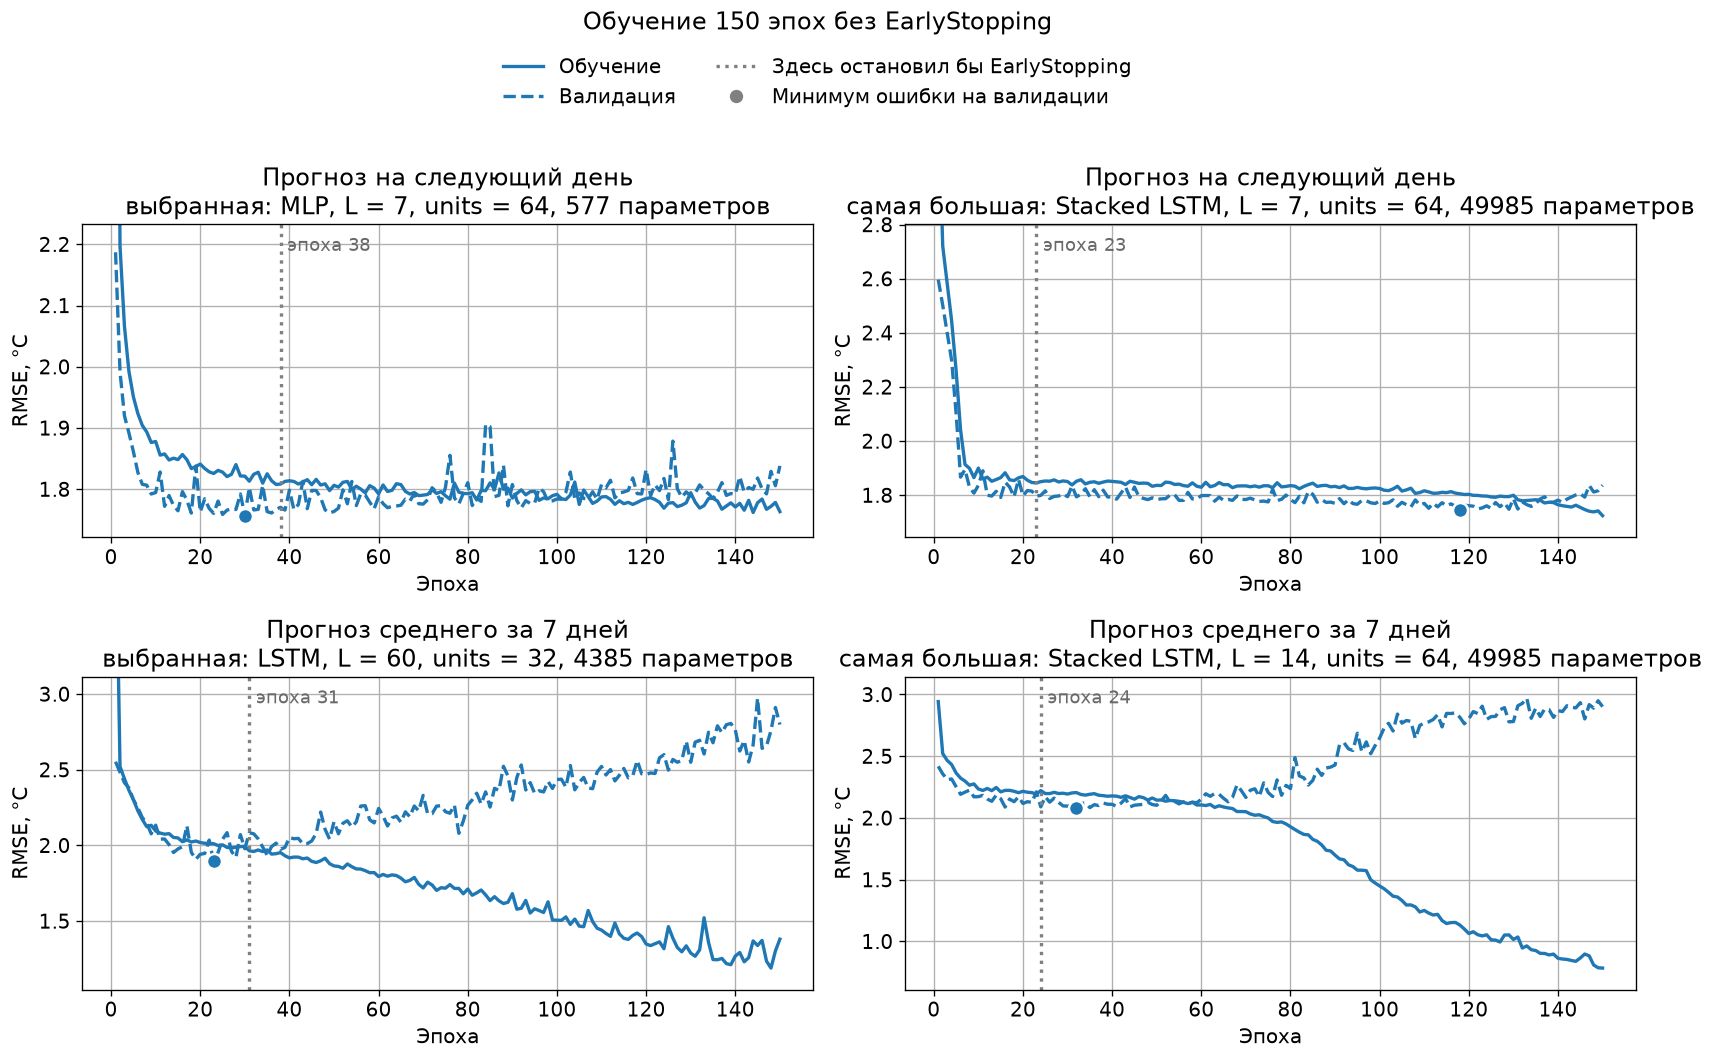

In [ ]:
# Кривые 150 эпох без EarlyStopping; вертикальная линия - где остановил бы EarlyStopping
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for axis, (role, record), history, row in zip(axes.ravel(), no_es_configs, no_es_histories,
                                              no_es_rows):
    curves, _ = draw_learning_curves(axis, history)
    axis.axvline(row["es_stop_epoch"], color="gray", linestyle=":", linewidth=2,
                 label="Здесь остановил бы EarlyStopping")
    # Номер эпохи остановки подписываем рядом с линией
    axis.annotate("эпоха " + str(row["es_stop_epoch"]), xy=(row["es_stop_epoch"], 1),
                  xycoords=("data", "axes fraction"), xytext=(4, -16),
                  textcoords="offset points", color="dimgray", fontsize=11)
    format_curves_axis(
        axis,
        TASK_TITLES[record["task"]].capitalize() + "\n" + role + ": " + config_text(record)
        + ", " + str(int(record["params"])) + " параметров",
        curves,
        legend=False,
    )

fig.suptitle("Обучение " + str(NO_ES_EPOCHS) + " эпох без EarlyStopping")
fig.tight_layout(rect=[0, 0, 1, add_figure_legend(fig, axes[0, 0], "Минимум ошибки на валидации",
                                                    columns=2)])
fig.savefig(FIGURES_DIR / "lab2-no-early-stopping.png", bbox_inches="tight")
plt.show()

**Результат:** числа из `results/lab2-no-early-stopping.csv`.

- Недельное среднее, выбранная LSTM: минимум ошибки на валидации - на 23-й эпохе (RMSE 1,8937 °C), это та же эпоха, которую восстановил EarlyStopping. Дальше ошибка на обучении падает до 1,3803 °C, а на валидации растет до 2,7985 °C к 150-й эпохе. Это явное переобучение: модель запоминает обучающий период, а на новых данных ошибается все сильнее.
- Недельное среднее, Stacked LSTM с 64 ячейками (49 985 параметров): ошибка на обучении падает до 0,7840 °C, на валидации растет до 2,9013 °C. Чем больше параметров, тем сильнее переобучение.
- Следующий день, выбранная MLP (577 параметров): минимум снова на 30-й эпохе (1,7567 °C), к 150-й эпохе на валидации 1,8380 °C при 1,7633 °C на обучении. Переобучение слабое: у маленькой сети мало возможностей запомнить шум.
- Следующий день, Stacked LSTM с 64 ячейками: EarlyStopping остановил ее на 23-й эпохе (1,7916 °C), а при долгом обучении минимум пришелся на 118-ю эпоху (1,7446 °C); к 150-й эпохе ошибка снова выросла до 1,8369 °C. Здесь patience 8 оказалось мало: кривая валидации долго идет почти горизонтально с колебаниями. Разница с выбранной MLP (1,7446 против 1,7567 °C) сравнима с разбросом между запусками (раздел 9), поэтому выбор модели не меняется.

Без EarlyStopping рекуррентные модели в задаче недельного среднего сильно переобучаются, поэтому EarlyStopping нужен. Во всех основных экспериментах он включен, и на их кривых переобучения не видно именно потому, что обучение останавливается вовремя.

### 9. Устойчивость моделей: повтор с разными SEED

Каждая конфигурация выше обучена один раз с SEED = 42. Результат зависит от начальных весов и порядка примеров в батчах, поэтому разница между моделями в сотые доли градуса может оказаться случайной. Здесь лучшая конфигурация каждой архитектуры для каждой задачи обучается пять раз с разными SEED и теми же остальными условиями.

Если разница между архитектурами больше разброса между запусками одной архитектуры, вывод о лучшей модели устойчив. Если меньше, модели на этих данных практически равны.

In [ ]:
# Этап 6: лучшая конфигурация каждой архитектуры, пять запусков с разными SEED
STABILITY_SEEDS = [42, 7, 123, 2024, 31337]

current = runs_frame()
# Лучшая по валидации конфигурация каждой архитектуры, как в итоговой таблице
stability_configs = (
    current.sort_values("val_RMSE").groupby(["task", "model"], as_index=False).head(1)
)

stability_rows = []
for _, record in stability_configs.iterrows():
    data = data_cache[(record["task"], int(record["window"]))]
    mask_train = data["split"] == "train"
    mask_val = data["split"] == "val"
    X_train = data["X"][mask_train]
    X_val = data["X"][mask_val]
    if record["model"] != "MLP":
        X_train = X_train[..., None]
        X_val = X_val[..., None]

    for seed in STABILITY_SEEDS:
        model = build_model(record["model"], int(record["window"]), int(record["units"]),
                            record["optimizer"], float(record["dropout"]), seed=seed)
        history, elapsed, early_stopping = train_model(
            model, X_train, data["y"][mask_train], X_val, data["y"][mask_val],
        )
        # Метрика в °C, как во всех таблицах
        pred_scaled = model.predict(X_val, verbose=0).ravel()
        pred = scaler.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()
        metrics = calc_metrics(data["y_raw"][mask_val], pred)
        stability_rows.append({
            "task": record["task"],
            "model": MODEL_TITLES[record["model"]],
            "window": int(record["window"]),
            "units": int(record["units"]),
            "params": int(record["params"]),
            "seed": seed,
            "epochs_run": len(history.history["loss"]),
            "val_RMSE": metrics["RMSE"],
        })
    print(record["task"], config_text(record), "- готово")

stability_runs = pd.DataFrame(stability_rows)
stability_table = (
    stability_runs.groupby(["task", "model", "window", "units", "params"], as_index=False)["val_RMSE"]
    .agg(mean="mean", std="std", min="min", max="max")
    .sort_values(["task", "mean"])
    .reset_index(drop=True)
)
stability_table[["mean", "std", "min", "max"]] = stability_table[["mean", "std", "min", "max"]].round(4)
stability_runs.round(4).to_csv(RESULTS_DIR / "lab2-stability-runs.csv", index=False, encoding="utf-8")
stability_table.to_csv(RESULTS_DIR / "lab2-stability.csv", index=False, encoding="utf-8")
display(stability_table)

next_day MLP, L = 7, units = 64 - готово


next_day LSTM, L = 60, units = 32 - готово


next_day SimpleRNN, L = 7, units = 32 - готово


next_day Stacked LSTM, L = 7, units = 32 - готово


weekly_mean LSTM, L = 60, units = 32 - готово


weekly_mean SimpleRNN, L = 60, units = 32 - готово


weekly_mean Stacked LSTM, L = 14, units = 32 - готово


weekly_mean MLP, L = 7, units = 32 - готово


,task,model,window,units,params,mean,std,min,max
0,next_day,MLP,7,64,577,1.7747,0.0160,1.7567,1.7928
1,next_day,SimpleRNN,7,32,1121,1.7874,0.0030,1.7848,1.7927
2,next_day,Stacked LSTM,7,32,12705,1.7881,0.0048,1.7836,1.7953
3,next_day,LSTM,60,32,4385,1.7931,0.0069,1.7819,1.7993
4,weekly_mean,LSTM,60,32,4385,1.9511,0.0412,1.8937,2.0014
5,weekly_mean,SimpleRNN,60,32,1121,2.0327,0.0284,2.0058,2.0730
6,weekly_mean,Stacked LSTM,14,32,12705,2.0869,0.0073,2.0744,2.0923
7,weekly_mean,MLP,7,32,289,2.1026,0.0103,2.0917,2.1165


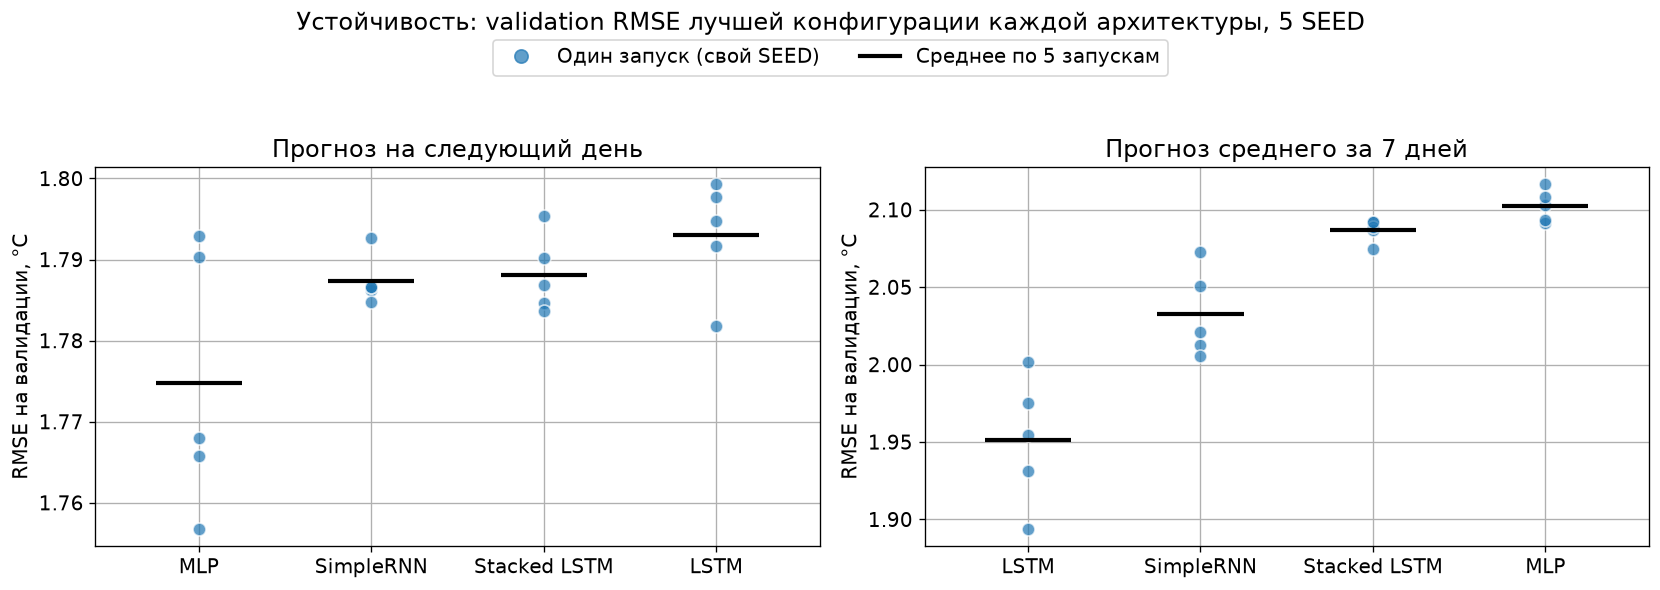

In [ ]:
# Разброс validation RMSE по пяти SEED: точка - один запуск, черта - среднее
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for axis, task in zip(axes, TASKS):
    task_table = stability_table[stability_table["task"] == task]
    for position, model_title in enumerate(task_table["model"]):
        values = stability_runs[(stability_runs["task"] == task)
                                & (stability_runs["model"] == model_title)]["val_RMSE"]
        axis.scatter(np.full(len(values), position), values, s=60, color="tab:blue",
                     alpha=0.7, edgecolor="white", zorder=3)
        axis.hlines(values.mean(), position - 0.25, position + 0.25, color="black",
                    linewidth=2.5, zorder=4)
    axis.set_xticks(range(len(task_table)))
    axis.set_xticklabels(task_table["model"])
    axis.set_xlim(-0.6, len(task_table) - 0.4)
    axis.set_title(TASK_TITLES[task].capitalize())
    axis.set_ylabel("RMSE на валидации, °C")

# Пояснение к маркерам одно на рисунок
handles = [
    Line2D([], [], marker="o", color="tab:blue", markersize=8, linestyle="none", alpha=0.7),
    Line2D([], [], color="black", linewidth=2.5),
]
fig.legend(handles, ["Один запуск (свой SEED)", "Среднее по 5 запускам"], loc="upper center",
           ncol=2, bbox_to_anchor=(0.5, 0.95))
fig.suptitle("Устойчивость: validation RMSE лучшей конфигурации каждой архитектуры, 5 SEED")
fig.tight_layout(rect=[0, 0, 1, 0.88])
fig.savefig(FIGURES_DIR / "lab2-stability.png", bbox_inches="tight")
plt.show()

**Результат:** числа из `results/lab2-stability.csv`, среднее и стандартное отклонение по пяти запускам.

- Недельное среднее: LSTM 1,9511 ± 0,0412 °C, SimpleRNN 2,0327 ± 0,0284, Stacked LSTM 2,0869 ± 0,0073, MLP 2,1026 ± 0,0103. LSTM лучше следующей за ней SimpleRNN в среднем на 0,08 °C, это больше разброса: выбор LSTM устойчив.
- Следующий день: MLP 1,7747 ± 0,0160 °C, SimpleRNN 1,7874 ± 0,0030, Stacked LSTM 1,7881 ± 0,0048, LSTM 1,7931 ± 0,0069. Средние отличаются меньше чем на 0,02 °C, диапазоны запусков пересекаются: на этой задаче четыре архитектуры практически равны. MLP остается выбранной моделью: у нее лучшее среднее и меньше всего параметров (577).
- У обеих выбранных моделей запуск с SEED = 42 оказался лучшим из пяти (1,7567 и 1,8937 °C). Поэтому validation RMSE выбранных моделей в таблицах немного оптимистичен: среднее по пяти запускам выше на 0,018 и 0,057 °C.
- Повторный запуск ноутбука на GPU может дать немного другие числа у рекуррентных моделей даже с тем же SEED: вычисления рекуррентных слоев на GPU (cuDNN) не полностью детерминированы. Разброс такого же порядка, как между разными SEED.

### 10. Кривые обучения лучших моделей

Для выбранной модели каждой задачи - кривые обучения и горизонтальная штриховая линия: RMSE этой модели на тестовой выборке в °C, то есть то же число, что в итоговой таблице.

,run_id,task,model,window,units,optimizer,dropout,params,epochs_run,best_epoch,train_time_s,val_MAE,val_MSE,val_RMSE,val_R2
0,11,next_day,MLP,7,64,adam,0.0,577,38,30,30.13,1.2570,3.0862,1.7567,0.9333
1,4,weekly_mean,LSTM,60,32,adam,0.0,4385,31,23,30.20,1.4849,3.5862,1.8937,0.9158


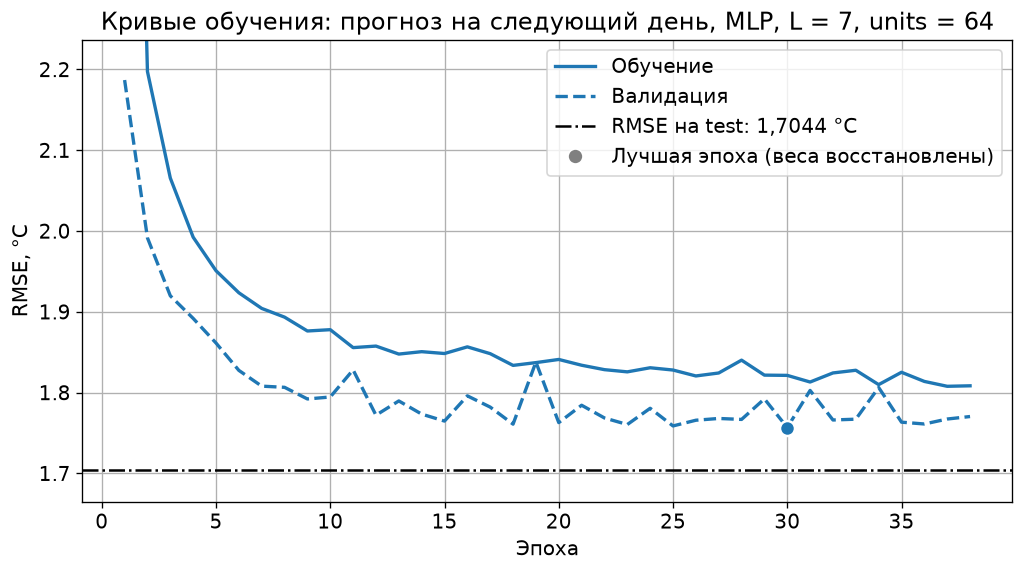

прогноз на следующий день: лучшая эпоха 30 из 38 , val RMSE = 1.7567 °C
RMSE на test: 1.7044 °C


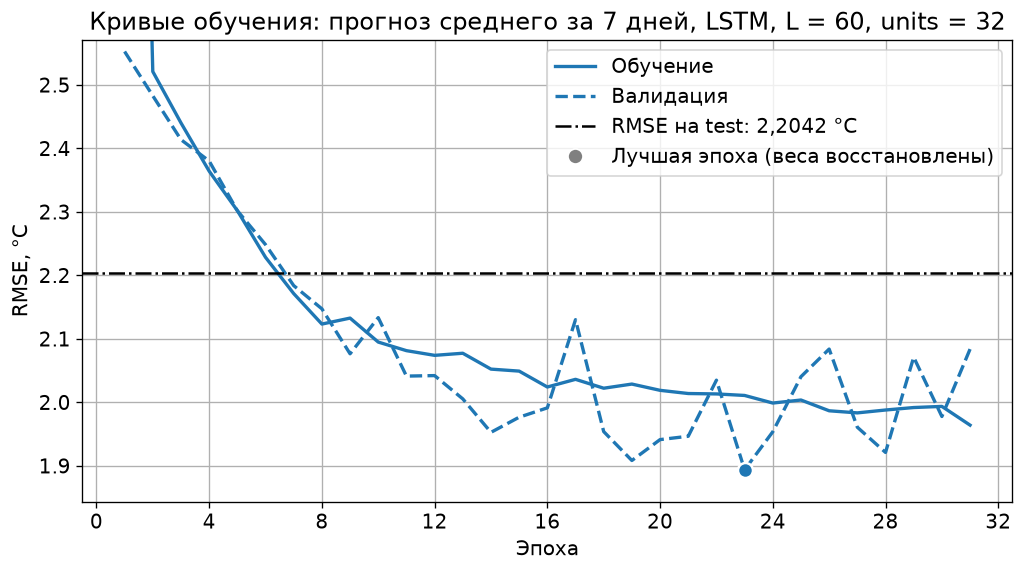

прогноз среднего за 7 дней: лучшая эпоха 23 из 31 , val RMSE = 1.8937 °C
RMSE на test: 2.2042 °C


In [ ]:
def evaluate_on_split(record, split_name):
    '''Считает прогноз и метрики выбранной модели на указанной выборке.'''
    data = data_cache[(record["task"], int(record["window"]))]
    mask = data["split"] == split_name
    X = data["X"][mask]
    if record["model"] != "MLP":
        X = X[..., None]

    model = trained_models[int(record["run_id"])]
    pred_scaled = model.predict(X, verbose=0).ravel()
    pred = scaler.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()
    metrics = calc_metrics(data["y_raw"][mask], pred)
    return metrics, pred, data["target_start"][mask], data["y_raw"][mask]


# Лучшая по validation конфигурация для каждой задачи
best_overall = (
    runs_frame()
    .sort_values("val_RMSE")
    .groupby("task", as_index=False)
    .head(1)
)
display(best_overall.reset_index(drop=True))

# Test: один раз оцениваем выбранную модель и строим кривые обучения
for _, record in best_overall.iterrows():
    test_metrics, _, _, _ = evaluate_on_split(record, "test")

    fig, ax = plt.subplots(figsize=(10, 5))
    curves, best_epoch = draw_learning_curves(ax, histories[int(record["run_id"])].history)
    ax.axhline(test_metrics["RMSE"], color="black", linestyle="-.", linewidth=1.5,
               label="RMSE на test: " + f"{test_metrics['RMSE']:.4f}".replace(".", ",") + " °C")
    format_curves_axis(ax, "Кривые обучения: " + TASK_TITLES[record["task"]] + ", "
                       + config_text(record), curves + [np.array([test_metrics["RMSE"]] * 2)])
    fig.savefig(FIGURES_DIR / ("lab2-curves-" + record["task"] + ".png"), bbox_inches="tight")
    plt.show()
    print_run_summary(TASK_TITLES[record["task"]], record)
    print("RMSE на test:", round(test_metrics["RMSE"], 4), "°C")

In [36]:
# Сохраняем лучшие модели и их конфигурации для воспроизводимости
for _, record in best_overall.iterrows():
    safe_name = record["task"].replace("_", "-")
    model_path = MODELS_DIR / ("lab2-" + safe_name + "-best.keras")
    trained_models[int(record["run_id"])].save(model_path)
    print("Сохранена модель:", model_path.name)

best_overall.drop(columns=["run_id"]).to_csv(
    RESULTS_DIR / "lab2-best-configs.csv", index=False, encoding="utf-8"
)
pd.DataFrame({"mean": [scaler.mean_[0]], "scale": [scaler.scale_[0]]}).to_csv(
    RESULTS_DIR / "lab2-scaler.csv", index=False, encoding="utf-8"
)

Сохранена модель: lab2-next-day-best.keras
Сохранена модель: lab2-weekly-mean-best.keras


**Результат:** у обеих выбранных моделей ошибка на обучении и на валидации быстро снижается и выходит на плато, EarlyStopping возвращает веса 30-й эпохи (MLP, следующий день) и 23-й эпохи (LSTM, недельное среднее). RMSE на тесте - 1,7044 и 2,2042 °C.

Для недельного среднего ошибка на тесте выше, чем на валидации (2,2042 против 1,8937 °C). Отчасти это потому, что валидационное число у этой модели - лучший из пяти запусков (раздел 9, среднее 1,9511 °C), отчасти потому, что тест - другой, более поздний период. Для следующего дня тест даже немного лучше валидации (1,7044 против 1,7567 °C): на тестовом интервале температура день ко дню менялась меньше (стандартное отклонение суточного изменения 1,71 °C против 1,93 °C на валидации).

## Итоговая оценка на тестовой выборке

Для каждой задачи берется лучшая по validation конфигурация каждой архитектуры, после чего все они один раз оцениваются на тесте. В таблицу также включены наивные прогнозы. Метрики считаются в градусах Цельсия.

In [37]:
# Итоговая таблица: лучшая модель каждого типа и базовые прогнозы на test
best_by_model = (
    runs_frame()
    .sort_values("val_RMSE")
    .groupby(["task", "model"], as_index=False)
    .head(1)
)

final_rows = []
for task in TASKS:
    task_best = best_by_model[best_by_model["task"] == task]
    for _, record in task_best.iterrows():
        metrics, _, _, _ = evaluate_on_split(record, "test")
        final_rows.append({
            "task": task,
            "model": MODEL_TITLES[record["model"]],
            "window": int(record["window"]),
            "units": int(record["units"]),
            "dropout": float(record["dropout"]),
            "params": int(record["params"]),
            **metrics,
        })

    data = make_task_data(task, min(WINDOW_LENGTHS))
    mask = data["split"] == "test"
    for method, title in [("persistence", "Naive (persistence)"), ("seasonal", "Seasonal naive")]:
        metrics = calc_metrics(data["y_raw"][mask], naive_predictions(data, method)[mask])
        final_rows.append({
            "task": task,
            "model": title,
            "window": np.nan,
            "units": np.nan,
            "dropout": np.nan,
            "params": np.nan,
            **metrics,
        })

final_table = pd.DataFrame(final_rows)
final_table[["MAE", "MSE", "RMSE", "R2"]] = final_table[["MAE", "MSE", "RMSE", "R2"]].round(4)

next_day_table = final_table[final_table["task"] == "next_day"].drop(columns="task")
weekly_table = final_table[final_table["task"] == "weekly_mean"].drop(columns="task")
next_day_table.to_csv(RESULTS_DIR / "lab2-next-day-metrics.csv", index=False, encoding="utf-8")
weekly_table.to_csv(RESULTS_DIR / "lab2-weekly-metrics.csv", index=False, encoding="utf-8")

print("Прогноз на следующий день")
display(next_day_table.reset_index(drop=True))
print("Прогноз среднего за 7 дней")
display(weekly_table.reset_index(drop=True))

Прогноз на следующий день


,model,window,units,dropout,params,MAE,MSE,RMSE,R2,n
0,MLP,7.0,64.0,0.0,577.0,1.2175,2.9050,1.7044,0.9458,549
1,LSTM,60.0,32.0,0.0,4385.0,1.2158,2.8011,1.6736,0.9477,549
2,SimpleRNN,7.0,32.0,0.0,1121.0,1.2361,2.8996,1.7028,0.9459,549
3,Stacked LSTM,7.0,32.0,0.0,12705.0,1.2174,2.8296,1.6821,0.9472,549
4,Naive (persistence),NaN,NaN,NaN,NaN,1.2386,2.9254,1.7104,0.9454,549
5,Seasonal naive,NaN,NaN,NaN,NaN,3.2556,16.8051,4.0994,0.6862,549


Прогноз среднего за 7 дней


,model,window,units,dropout,params,MAE,MSE,RMSE,R2,n
0,LSTM,60.0,32.0,0.0,4385.0,1.6116,4.8585,2.2042,0.9026,543
1,SimpleRNN,60.0,32.0,0.0,1121.0,1.5994,4.6617,2.1591,0.9065,543
2,Stacked LSTM,14.0,32.0,0.0,12705.0,1.6709,4.8803,2.2091,0.9021,543
3,MLP,7.0,32.0,0.0,289.0,1.7427,5.4030,2.3244,0.8916,543
4,Naive (persistence),NaN,NaN,NaN,NaN,2.0021,7.2089,2.6849,0.8554,543
5,Seasonal naive,NaN,NaN,NaN,NaN,2.6979,11.0069,3.3177,0.7792,543


**Результат:** на тесте все нейросети превзошли persistence. Для следующего дня: MLP - RMSE 1,7044 °C (R2 0,9458); LSTM - RMSE 1,6736 °C (R2 0,9477); SimpleRNN - RMSE 1,7028 °C (R2 0,9459); Stacked LSTM - RMSE 1,6821 °C (R2 0,9472); Naive (persistence) - RMSE 1,7104 °C (R2 0,9454); Seasonal naive - RMSE 4,0994 °C (R2 0,6862). Лучший RMSE у LSTM. Для недельного среднего: LSTM - RMSE 2,2042 °C (R2 0,9026); SimpleRNN - RMSE 2,1591 °C (R2 0,9065); Stacked LSTM - RMSE 2,2091 °C (R2 0,9021); MLP - RMSE 2,3244 °C (R2 0,8916); Naive (persistence) - RMSE 2,6849 °C (R2 0,8554); Seasonal naive - RMSE 3,3177 °C (R2 0,7792). Лучший RMSE у SimpleRNN. Все модели достигли R2 выше 0,89, то есть ориентир 0,80 выполнен.

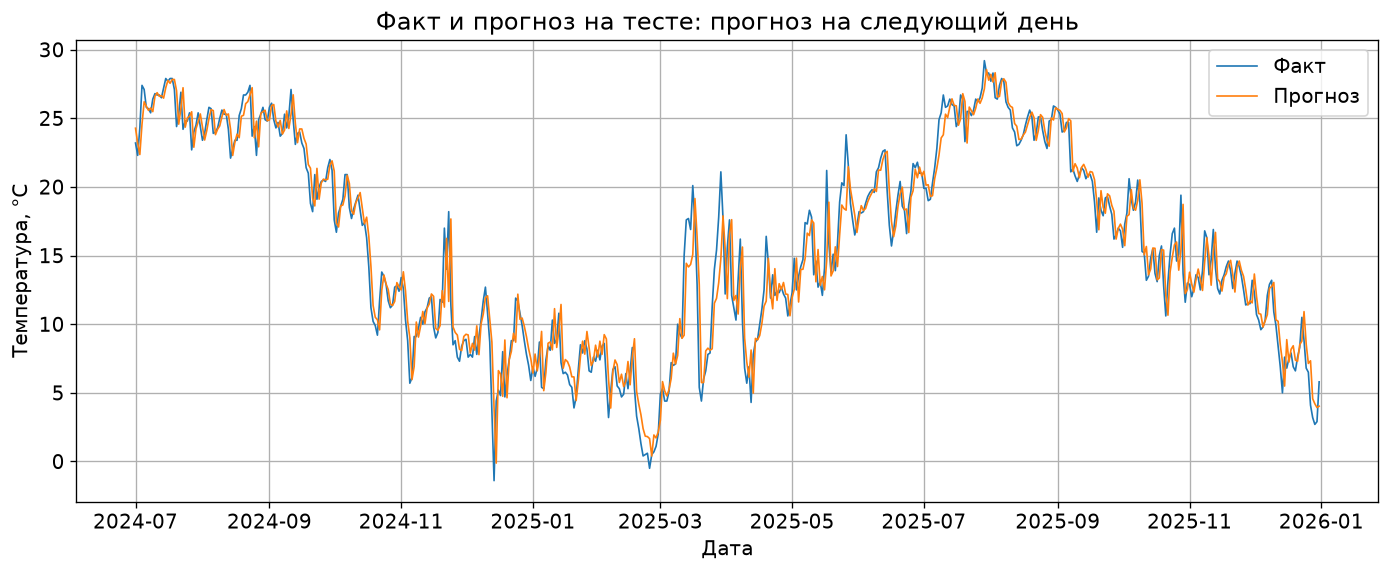

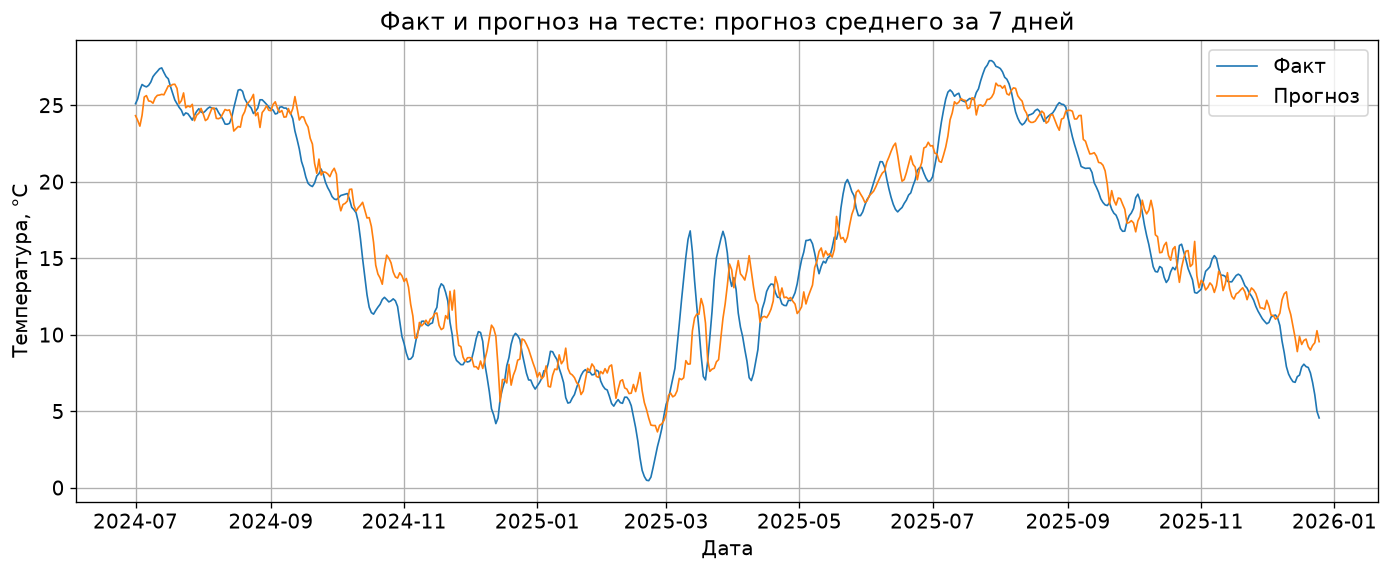

In [38]:
# График "факт - прогноз" для выбранной модели каждой задачи
for _, record in best_overall.iterrows():
    metrics, pred, dates, true = evaluate_on_split(record, "test")
    title = TASK_TITLES[record["task"]]

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(dates, true, color="tab:blue", linewidth=1.0, label="Факт")
    ax.plot(dates, pred, color="tab:orange", linewidth=1.0, label="Прогноз")
    ax.set_title("Факт и прогноз на тесте: " + title)
    ax.set_xlabel("Дата")
    ax.set_ylabel("Температура, °C")
    ax.legend()
    fig.savefig(FIGURES_DIR / ("lab2-forecast-" + record["task"] + ".png"), bbox_inches="tight")
    plt.show()

**Результат:** на тестовом интервале обе выбранные модели повторяют сезонный ход температуры. Для следующего дня MLP (RMSE 1,7044 °C, R² 0,9458) хорошо отслеживает суточные колебания, но сглаживает отдельные резкие всплески. Для недельного среднего LSTM (RMSE 2,2042 °C, R² 0,9026) даёт более гладкую кривую, что ожидаемо для среднего за семь дней. Систематического сдвига на всём интервале не видно.

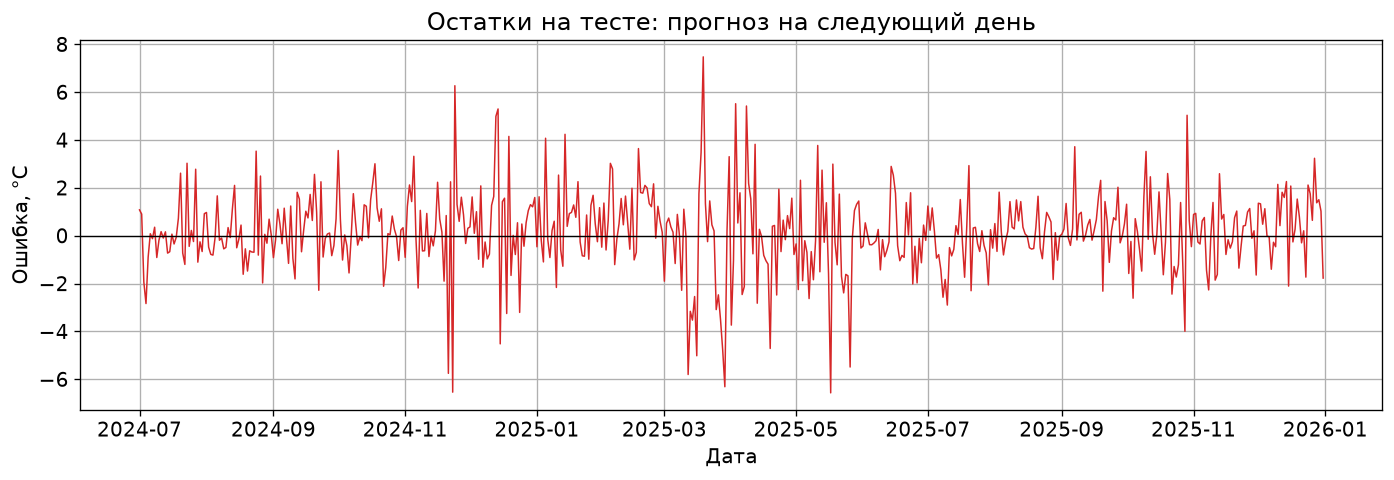

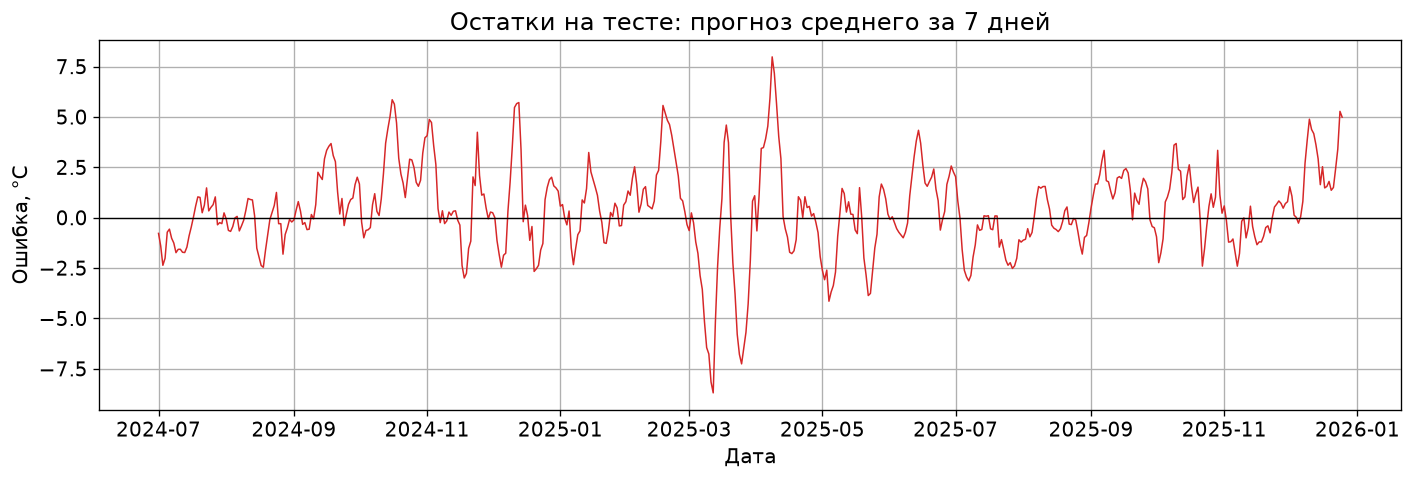

In [39]:
# График остатков: проверяем смещение и разброс ошибки
for _, record in best_overall.iterrows():
    metrics, pred, dates, true = evaluate_on_split(record, "test")
    residuals = pred - true
    title = TASK_TITLES[record["task"]]

    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(dates, residuals, color="tab:red", linewidth=0.9)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title("Остатки на тесте: " + title)
    ax.set_xlabel("Дата")
    ax.set_ylabel("Ошибка, °C")
    fig.savefig(FIGURES_DIR / ("lab2-residuals-" + record["task"] + ".png"), bbox_inches="tight")
    plt.show()

**Результат:** остатки обеих моделей колеблются вокруг нуля без выраженного тренда, то есть систематического смещения нет. Для следующего дня разброс ошибок больше, а отдельные всплески совпадают с резкими изменениями погоды; для недельного среднего остатки меньше и глаже за счёт усреднения. Ошибка на test сопоставима с validation, поэтому признаков переобучения по остаткам не видно.

## Дополнительный эксперимент: другие погодные признаки

В основных экспериментах модель видела только среднюю температуру за прошлые дни. Здесь обе задачи проверяются с расширенным входом: в лучшие конфигурации каждой задачи подаются еще несколько погодных признаков, и по validation и test видно, дает ли это прирост качества или только усложняет модель.

Кандидаты: минимальная и максимальная температура, осадки, скорость и направление ветра, давление, высота снега, порыв ветра и продолжительность солнца. Сначала каждый признак проверяется на пропуски, выбросы и связь с целевой температурой.

### Проверка кандидатов

Пропуски и выбросы считаем по всему ряду, а границы выбросов по правилу 1,5 IQR - только по train, чтобы не подглядывать в validation и test.

In [40]:
# Кандидаты в дополнительные признаки: пропуски, выбросы и связь с целевой температурой
CANDIDATE_FEATURES = ["tmin", "tmax", "prcp", "wspd", "pres", "wdir", "snow", "wpgt", "tsun"]
train_mask_features = weather["date"] <= train_end

candidate_rows = []
for feature in CANDIDATE_FEATURES:
    values_train = weather.loc[train_mask_features, feature]
    has_values = bool(values_train.notna().any())
    q1 = values_train.quantile(0.25)
    q3 = values_train.quantile(0.75)
    spread = q3 - q1
    lower_bound = q1 - 1.5 * spread
    upper_bound = q3 + 1.5 * spread
    outliers = ((weather[feature] < lower_bound) | (weather[feature] > upper_bound)).sum()

    candidate_rows.append({
        "признак": feature,
        "пропусков": int(weather[feature].isna().sum()),
        "доля пропусков, %": round(100 * float(weather[feature].isna().mean()), 1),
        "асимметрия": round(float(weather[feature].skew()), 2) if has_values else np.nan,
        "выбросов по 1,5 IQR": int(outliers) if has_values else np.nan,
        "корреляция с tavg": round(float(weather[feature].corr(weather["tavg"])), 3) if has_values else np.nan,
    })

candidate_table = pd.DataFrame(candidate_rows)
display(candidate_table)

,признак,пропусков,"доля пропусков, %",асимметрия,"выбросов по 1,5 IQR",корреляция с tavg
0,tmin,0,0.0,0.03,0.0,0.973
1,tmax,1,0.0,-0.13,0.0,0.978
2,prcp,201,5.5,4.28,687.0,-0.144
3,wspd,25,0.7,0.79,100.0,-0.076
4,pres,99,2.7,0.25,6.0,-0.630
5,wdir,259,7.1,0.95,164.0,0.262
6,snow,3629,99.3,0.91,0.0,-0.208
7,wpgt,3653,100.0,NaN,NaN,NaN
8,tsun,3653,100.0,NaN,NaN,NaN


**Результат:** четыре кандидата отпадают сразу. `tmin` и `tmax` почти повторяют `tavg` (корреляция 0,973 и 0,978) - это мультиколлинеарность: новой информации они не добавляют, только увеличивают размер входа. `wpgt` и `tsun` пусты полностью, `snow` имеет 3629 пропусков (99,3 %), а `wdir` - круговой угол, где 0 и 360 градусов означают одно направление, поэтому его нужно кодировать синусом и косинусом, а не подавать как число. Остаются `prcp`, `wspd` и `pres`; пропусков у них 201 (5,5 %), 25 (0,7 %) и 99 (2,7 %), их заполняем медианами train. По правилу 1,5 IQR формально выходит 687, 100 и 6 выбросов. Для осадков правило непригодно: медиана равна нулю, поэтому каждый дождь попадает за верхнюю границу, а распределение сильно скошено (асимметрия 4,28). Вместо удаления или обрезки применяем логарифм `log1p`: он сжимает тяжелый хвост и сохраняет информацию о сильных дождях. У `wspd` и `pres` выбросов мало (2,7 % и 0,2 %), это реальные шторма и аномалии давления, поэтому строки не удаляем.

### Подготовка признаков

Средняя температура берется уже в масштабе `scaler`, обученном на train в основном эксперименте, поэтому цели и метрики остаются сопоставимыми. Три дополнительных признака заполняются медианами train и масштабируются отдельным `StandardScaler`, который тоже обучается только на train. Осадки перед масштабированием переводятся в логарифмическую шкалу `log1p`: так редкие ливни не доминируют в масштабе и информация о них сохраняется.

In [41]:
# Дополнительные признаки, которые прошли проверку: осадки, скорость ветра и давление
EXTRA_FEATURES = ["prcp", "wspd", "pres"]
FEATURE_COLUMNS = ["tavg"] + EXTRA_FEATURES


def prepare_extra_features(frame):
    '''Возвращает дополнительные признаки с логарифмом осадков.'''
    prepared = frame[EXTRA_FEATURES].copy()
    prepared["prcp"] = np.log1p(prepared["prcp"])
    return prepared


# Медианы для заполнения пропусков - только по train
train_prepared = prepare_extra_features(weather.loc[train_mask_features])
fill_values = train_prepared.median()
extra_filled = prepare_extra_features(weather).fillna(fill_values)

# Масштабирование тоже обучаем только на train
feature_scaler = StandardScaler()
feature_scaler.fit(extra_filled.loc[train_mask_features])
extra_scaled = feature_scaler.transform(extra_filled).astype("float32")

# Вход одного дня: средняя температура в масштабе основного эксперимента плюс три признака
model_input = np.column_stack([
    weather["tavg_scaled"].to_numpy(dtype="float32"),
    extra_scaled,
]).astype("float32")

print("Пропусков в дополнительных признаках до заполнения:", int(weather[EXTRA_FEATURES].isna().sum().sum()))
print("Форма входа одного дня:", model_input.shape)
display(pd.DataFrame({
    "признак": EXTRA_FEATURES,
    "медиана train": fill_values.to_numpy().round(3),
    "среднее train": feature_scaler.mean_.round(3),
    "стандартное отклонение": feature_scaler.scale_.round(3),
}))

Пропусков в дополнительных признаках до заполнения: 325
Форма входа одного дня: (3653, 4)


,признак,медиана train,среднее train,стандартное отклонение
0,prcp,0.0,0.631,1.098
1,wspd,11.4,11.680,2.887
2,pres,1015.1,1015.359,5.914


### Скользящие окна

Окна строятся так же, как в основном эксперименте: те же длины, те же цели для обеих задач и та же разметка по датам, но в каждом дне окна теперь четыре числа вместо одного. Для MLP окно разворачивается в плоский вектор, рекуррентные модели получают последовательность из четырех признаков.

In [42]:
def make_feature_data(task, window):
    '''Строит окна из четырех признаков; цели и разбиение совпадают с базовым экспериментом.'''
    values_scaled = weather["tavg_scaled"].to_numpy(dtype="float32")
    values_raw = weather["tavg"].to_numpy(dtype="float32")
    dates = pd.DatetimeIndex(weather["date"])
    horizon = 1 if task == "next_day" else WEEKLY_HORIZON

    X, y_scaled, y_raw, target_start, target_end = [], [], [], [], []
    last_start = len(weather) - horizon
    for i in range(window, last_start + 1):
        # Вход - окно из window дней, в каждом дне четыре признака
        X.append(model_input[i - window:i])
        if task == "next_day":
            y_scaled.append(values_scaled[i])
            y_raw.append(values_raw[i])
        else:
            y_scaled.append(values_scaled[i:i + horizon].mean())
            y_raw.append(values_raw[i:i + horizon].mean())
        target_start.append(dates[i])
        target_end.append(dates[i + horizon - 1])

    X = np.asarray(X, dtype="float32")
    y_scaled = np.asarray(y_scaled, dtype="float32")
    y_raw = np.asarray(y_raw, dtype="float32")
    target_start = pd.DatetimeIndex(target_start)
    target_end = pd.DatetimeIndex(target_end)

    # Та же разметка по датам цели: окна на стыке выборок попадают в gap
    split = np.full(len(y_scaled), "gap", dtype=object)
    split[target_end <= train_end] = "train"
    split[(target_start >= val_start) & (target_end <= val_end)] = "val"
    split[target_start >= test_start] = "test"

    return {
        "task": task,
        "window": window,
        "X": X,
        "y": y_scaled,
        "y_raw": y_raw,
        "target_start": target_start,
        "target_end": target_end,
        "split": split,
    }


# MLP получает плоское окно, рекуррентные модели - последовательность из четырех признаков
def reshape_for_model(X, model_type):
    if model_type == "MLP":
        return X.reshape(len(X), -1)
    return X

### Обучение и сравнение

Каждая из четырех лучших конфигураций каждой задачи обучается заново на тех же окнах и с теми же правилами: MSE, batch size 32, до 80 эпох, EarlyStopping с patience 8, тот же оптимизатор и Dropout. Отличается только вход: вместо одного числа в день модель получает четыре признака. После обучения те же конфигурации один раз оцениваются на test.

In [43]:
# Те же лучшие конфигурации обеих задач, но с четырьмя признаками
best_configs = best_by_model.copy()

extra_rows = []
for _, record in best_configs.iterrows():
    data = make_feature_data(record["task"], int(record["window"]))
    masks = {name: data["split"] == name for name in ("train", "val", "test")}

    # Архитектура, число ячеек, оптимизатор и Dropout те же, меняется только вход
    model = build_model(
        record["model"],
        int(record["window"]),
        int(record["units"]),
        record["optimizer"],
        float(record["dropout"]),
        n_features=len(FEATURE_COLUMNS),
    )
    history, elapsed, early_stopping = train_model(
        model,
        reshape_for_model(data["X"][masks["train"]], record["model"]),
        data["y"][masks["train"]],
        reshape_for_model(data["X"][masks["val"]], record["model"]),
        data["y"][masks["val"]],
    )

    # Метрики в градусах Цельсия: прогноз возвращаем обратным масштабированием
    split_metrics = {}
    for split_name in ("val", "test"):
        X = reshape_for_model(data["X"][masks[split_name]], record["model"])
        pred_scaled = model.predict(X, verbose=0).ravel()
        pred = scaler.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()
        split_metrics[split_name] = calc_metrics(data["y_raw"][masks[split_name]], pred)

    extra_rows.append({
        "task": record["task"],
        "model": record["model"],
        "features": len(FEATURE_COLUMNS),
        "window": int(record["window"]),
        "units": int(record["units"]),
        "params": int(model.count_params()),
        "val_RMSE": split_metrics["val"]["RMSE"],
        "val_R2": split_metrics["val"]["R2"],
        "test_RMSE": split_metrics["test"]["RMSE"],
        "test_R2": split_metrics["test"]["R2"],
    })
    print(
        record["task"], MODEL_TITLES[record["model"]],
        "L =", int(record["window"]), "units =", int(record["units"]),
        "эпох =", len(history.history["loss"]),
        "val RMSE =", round(split_metrics["val"]["RMSE"], 4),
        "test RMSE =", round(split_metrics["test"]["RMSE"], 4),
        "время =", round(elapsed, 1), "с",
    )

extra_table = pd.DataFrame(extra_rows)
display(extra_table.round(4).reset_index(drop=True))

next_day MLP L = 7 units = 64 эпох = 32 val RMSE = 2.0164 test RMSE = 1.8263 время = 24.1 с


next_day LSTM L = 60 units = 32 эпох = 51 val RMSE = 1.7034 test RMSE = 1.6025 время = 49.3 с


next_day SimpleRNN L = 7 units = 32 эпох = 32 val RMSE = 1.7637 test RMSE = 1.6638 время = 49.9 с


next_day Stacked LSTM L = 7 units = 32 эпох = 32 val RMSE = 1.7232 test RMSE = 1.6331 время = 39.4 с


weekly_mean LSTM L = 60 units = 32 эпох = 13 val RMSE = 2.2425 test RMSE = 2.4254 время = 12.7 с


weekly_mean SimpleRNN L = 60 units = 32 эпох = 22 val RMSE = 2.0496 test RMSE = 2.1263 время = 129.3 с


weekly_mean Stacked LSTM L = 14 units = 32 эпох = 22 val RMSE = 2.3396 test RMSE = 2.3286 время = 26.7 с


weekly_mean MLP L = 7 units = 32 эпох = 23 val RMSE = 2.2043 test RMSE = 2.422 время = 18.5 с


,task,model,features,window,units,params,val_RMSE,val_R2,test_RMSE,test_R2
0,next_day,MLP,4,7,64,1921,2.0164,0.9122,1.8263,0.9377
1,next_day,LSTM,4,60,32,4769,1.7034,0.9373,1.6025,0.9521
2,next_day,SimpleRNN,4,7,32,1217,1.7637,0.9328,1.6638,0.9483
3,next_day,StackedLSTM,4,7,32,13089,1.7232,0.9359,1.6331,0.9502
4,weekly_mean,LSTM,4,60,32,4769,2.2425,0.8819,2.4254,0.8820
5,weekly_mean,SimpleRNN,4,60,32,1217,2.0496,0.9014,2.1263,0.9093
6,weekly_mean,StackedLSTM,4,14,32,13089,2.3396,0.8715,2.3286,0.8912
7,weekly_mean,MLP,4,7,32,961,2.2043,0.8859,2.4220,0.8823


In [44]:
# Сравнение на validation и test для обеих задач: одна температура против четырех признаков
base_rows = []
for _, record in best_configs.iterrows():
    test_row = final_table[
        (final_table["task"] == record["task"])
        & (final_table["model"] == MODEL_TITLES[record["model"]])
    ].iloc[0]
    base_rows.append({
        "task": record["task"],
        "model": record["model"],
        "features": 1,
        "window": int(record["window"]),
        "units": int(record["units"]),
        "params": int(record["params"]),
        "val_RMSE": float(record["val_RMSE"]),
        "val_R2": float(record["val_R2"]),
        "test_RMSE": float(test_row["RMSE"]),
        "test_R2": float(test_row["R2"]),
    })
base_table = pd.DataFrame(base_rows)

# Длинная таблица: каждая конфигурация в двух вариантах набора признаков
feature_comparison = pd.concat([base_table, extra_table], ignore_index=True)
feature_comparison["model"] = feature_comparison["model"].map(MODEL_TITLES)
feature_comparison["features"] = feature_comparison["features"].map(
    lambda count: "только tavg" if count == 1 else "четыре признака"
)
feature_comparison = feature_comparison[
    ["task", "model", "features", "window", "units", "params", "val_RMSE", "val_R2", "test_RMSE", "test_R2"]
]
feature_comparison.round(4).to_csv(
    RESULTS_DIR / "lab2-extra-features.csv", index=False, encoding="utf-8"
)
display(feature_comparison.round(4).reset_index(drop=True))

# Прирост качества: отрицательная разница RMSE означает улучшение
delta_rows = []
for task, model_title in feature_comparison[["task", "model"]].drop_duplicates().itertuples(index=False):
    base = feature_comparison[
        (feature_comparison["task"] == task)
        & (feature_comparison["model"] == model_title)
        & (feature_comparison["features"] == "только tavg")
    ].iloc[0]
    extra = feature_comparison[
        (feature_comparison["task"] == task)
        & (feature_comparison["model"] == model_title)
        & (feature_comparison["features"] == "четыре признака")
    ].iloc[0]
    delta_rows.append({
        "task": task,
        "model": model_title,
        "d_RMSE_val": extra["val_RMSE"] - base["val_RMSE"],
        "d_RMSE_test": extra["test_RMSE"] - base["test_RMSE"],
        "d_R2_test": extra["test_R2"] - base["test_R2"],
    })
delta_table = pd.DataFrame(delta_rows)
display(delta_table.round(4).reset_index(drop=True))

,task,model,features,window,units,params,val_RMSE,val_R2,test_RMSE,test_R2
0,next_day,MLP,только tavg,7,64,577,1.7567,0.9333,1.7044,0.9458
1,next_day,LSTM,только tavg,60,32,4385,1.7814,0.9315,1.6736,0.9477
2,next_day,SimpleRNN,только tavg,7,32,1121,1.7863,0.9311,1.7028,0.9459
3,next_day,Stacked LSTM,только tavg,7,32,12705,1.7868,0.9310,1.6821,0.9472
4,weekly_mean,LSTM,только tavg,60,32,4385,1.8937,0.9158,2.2042,0.9026
5,weekly_mean,SimpleRNN,только tavg,60,32,1121,1.9804,0.9079,2.1591,0.9065
6,weekly_mean,Stacked LSTM,только tavg,14,32,12705,2.0744,0.8989,2.2091,0.9021
7,weekly_mean,MLP,только tavg,7,32,289,2.0917,0.8973,2.3244,0.8916
8,next_day,MLP,четыре признака,7,64,1921,2.0164,0.9122,1.8263,0.9377
9,next_day,LSTM,четыре признака,60,32,4769,1.7034,0.9373,1.6025,0.9521


,task,model,d_RMSE_val,d_RMSE_test,d_R2_test
0,next_day,MLP,0.2597,0.1219,-0.0081
1,next_day,LSTM,-0.0780,-0.0711,0.0044
2,next_day,SimpleRNN,-0.0226,-0.0390,0.0024
3,next_day,Stacked LSTM,-0.0636,-0.0490,0.0030
4,weekly_mean,LSTM,0.3488,0.2212,-0.0206
5,weekly_mean,SimpleRNN,0.0692,-0.0328,0.0028
6,weekly_mean,Stacked LSTM,0.2652,0.1195,-0.0109
7,weekly_mean,MLP,0.1126,0.0976,-0.0093


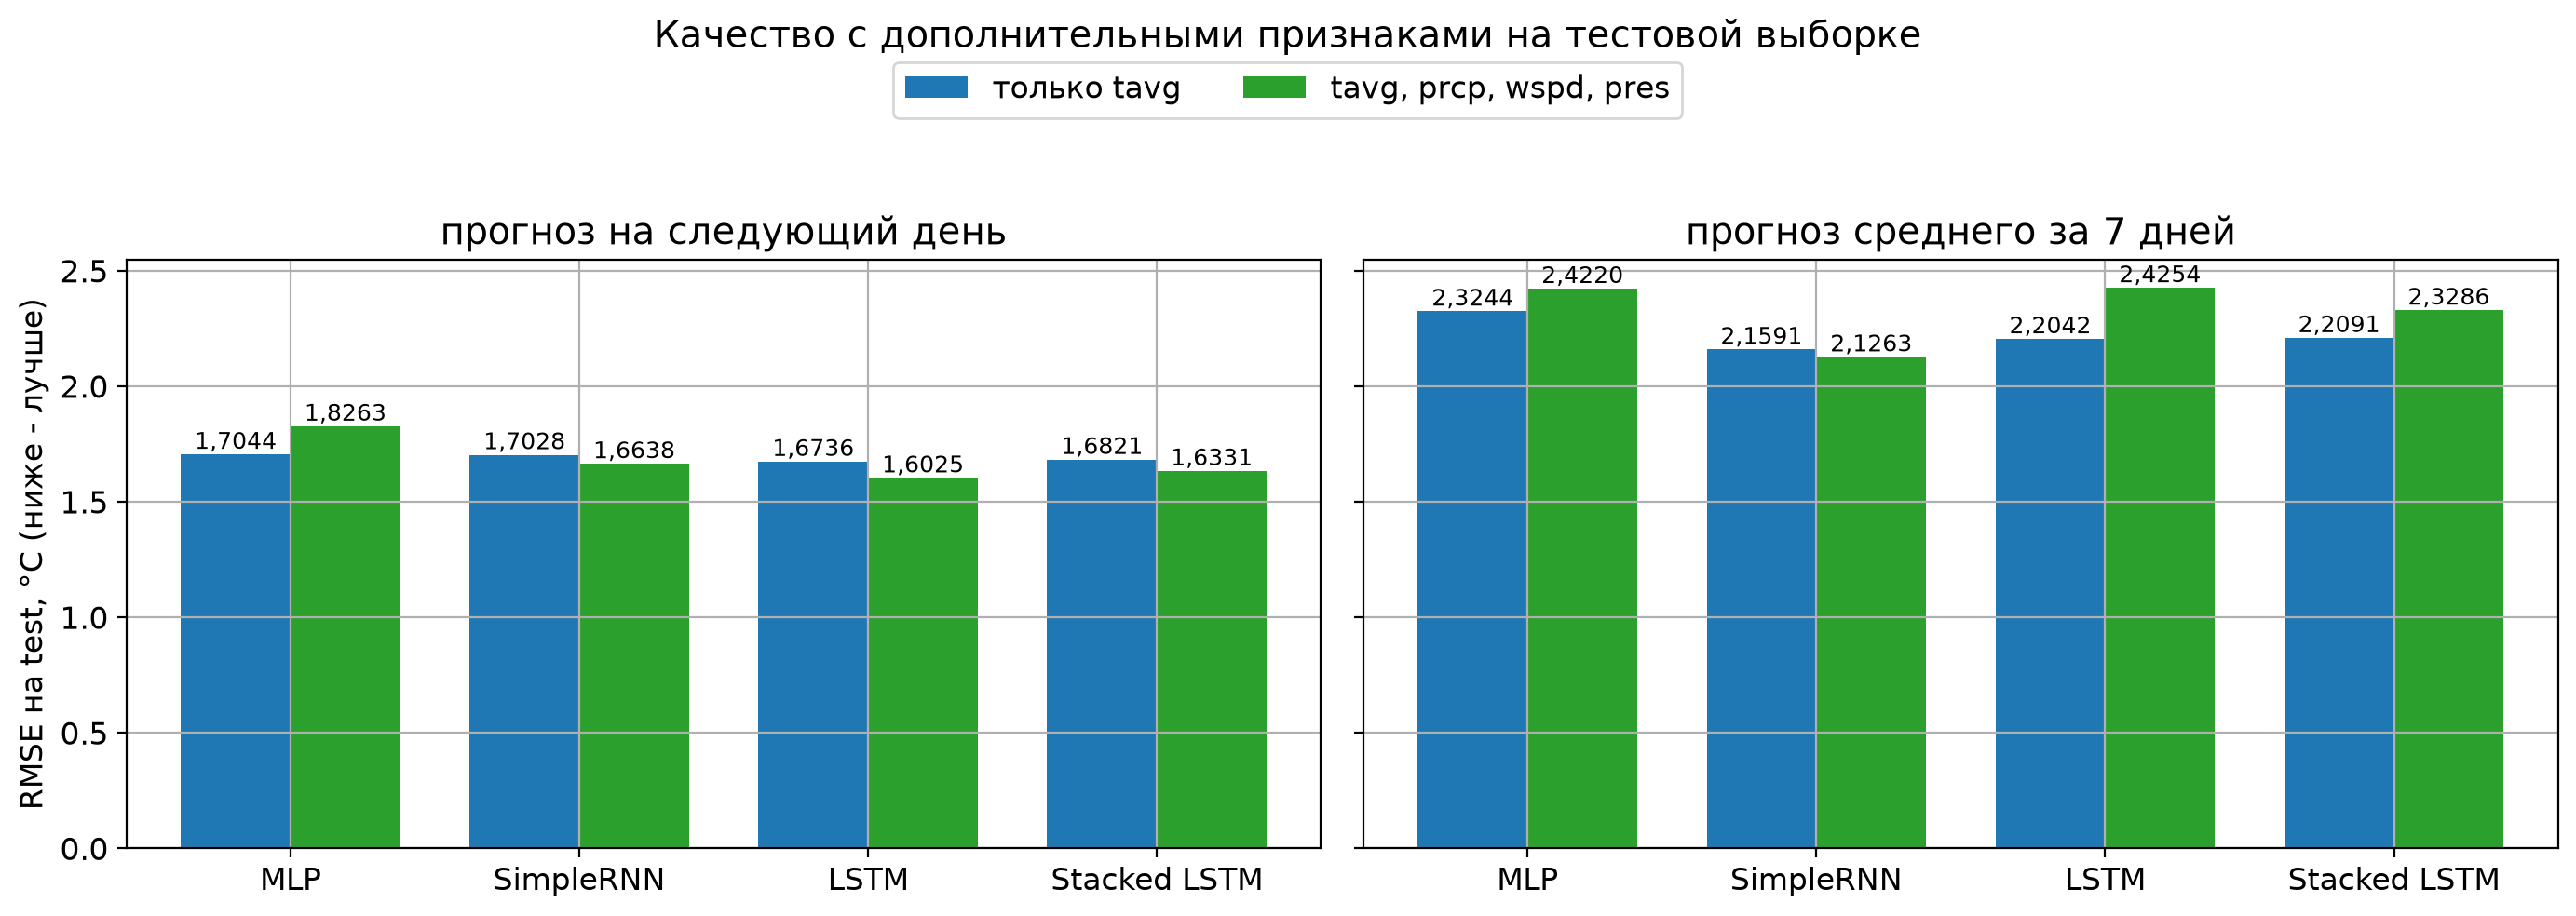

In [ ]:
# RMSE на test: одна температура против четырех признаков, отдельная панель для каждой задачи
def comparison_value(task, model_title, feature_title):
    '''Достает RMSE на test для нужной задачи и варианта набора признаков.'''
    row = feature_comparison[
        (feature_comparison["task"] == task)
        & (feature_comparison["model"] == model_title)
        & (feature_comparison["features"] == feature_title)
    ].iloc[0]
    return float(row["test_RMSE"])


width = 0.38
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for position, (axis, task) in enumerate(zip(axes, TASKS)):
    # Одинаковый порядок моделей на обеих панелях: от простой к сложной,
    # чтобы одну и ту же архитектуру было легко найти слева и справа
    task_models = set(best_configs.loc[best_configs["task"] == task, "model"])
    model_titles = [MODEL_TITLES[model_type] for model_type in MODEL_TITLES if model_type in task_models]
    positions = np.arange(len(model_titles))
    base_values = [comparison_value(task, title, "только tavg") for title in model_titles]
    extra_values = [comparison_value(task, title, "четыре признака") for title in model_titles]

    bars_base = axis.bar(positions - width / 2, base_values, width,
                         label="только tavg", color="tab:blue")
    bars_extra = axis.bar(positions + width / 2, extra_values, width,
                          label="tavg, prcp, wspd, pres", color="tab:green")
    axis.set_xticks(positions)
    axis.set_xticklabels(model_titles)
    axis.set_title(TASK_TITLES[task])
    if position == 0:
        axis.set_ylabel("RMSE на test, °C (ниже - лучше)")
    for bar in list(bars_base) + list(bars_extra):
        axis.annotate(
            f"{bar.get_height():.4f}".replace(".", ","),
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            ha="center", va="bottom", fontsize=9,
        )

# Одна общая легенда над панелями, чтобы она не закрывала столбцы
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 0.95))
fig.suptitle("Качество с дополнительными признаками на тестовой выборке")
fig.tight_layout(rect=[0, 0, 1, 0.88])
fig.savefig(FIGURES_DIR / "lab2-extra-features.png", bbox_inches="tight")
plt.show()

**Результат:** дополнительные признаки дали разный эффект в двух задачах. По валидации, по которой в работе принимаются решения, они помогли трем рекуррентным моделям на следующем дне: LSTM 1,7814 -> 1,7034 °C, Stacked LSTM 1,7868 -> 1,7232 °C, SimpleRNN 1,7863 -> 1,7637 °C; MLP ухудшилась (1,7567 -> 2,0164 °C). На недельном среднем по валидации хуже стали все четыре модели. Тест показывает ту же картину. Для следующего дня три рекуррентные модели улучшились: LSTM - RMSE 1,6736 -> 1,6025 °C (R2 0,9477 -> 0,9521), Stacked LSTM - 1,6821 -> 1,6331 °C, SimpleRNN - 1,7028 -> 1,6638 °C. MLP, наоборот, ухудшилась: 1,7044 -> 1,8263 °C. Для недельного среднего выигрыш только у SimpleRNN: 2,1591 -> 2,1263 °C (R2 0,9065 -> 0,9093), а LSTM (2,2042 -> 2,4254 °C), Stacked LSTM (2,2091 -> 2,3286 °C) и MLP (2,3244 -> 2,4220 °C) стали хуже. Причина в самой задаче: для следующего дня давление и температура текущего момента прямо связаны с погодой, поэтому дополнительные входы помогают, а для среднего за следующие семь дней осадки, ветер и давление почти не несут информации о будущем и работают как шум. Это видно и по validation: у LSTM на недельном среднем ошибка выросла с 1,8937 до 2,2425 °C. У SimpleRNN на недельном среднем validation тоже ухудшилась (1,9804 -> 2,0496 °C), а test немного улучшился, поэтому уверенного выигрыша здесь нет. LSTM с четырьмя признаками на следующий день лучше выбранной MLP и по валидации (1,7034 против 1,7567 °C), и разница больше разброса между запусками. В основной выбор этот вариант не включен, потому что это другая постановка с другим входом, а основное сравнение по заданию идет по истории температуры. Для прогноза на следующий день это готовое улучшение, оно указано в выводе.

## Вывод:

В работе построены четыре нейросетевые модели для двух задач прогнозирования температуры в Сочи по данным Meteostat за 2016-2025 годы. Данные проверены на пропуски, дубликаты и выбросы, разбиты строго по времени, масштабирование обучено только на train, целевые интервалы validation и test не пересекаются с train.

Лучшей по validation для следующего дня стала MLP с окном 7 дней и 64 нейронами (RMSE 1,7567 °C, R2 0,9333). На тесте: RMSE 1,7044 °C, R2 0,9458. Лучшей по validation для недельного среднего стала LSTM с окном 60 дней и 32 ячейками (RMSE 1,8937 °C, R2 0,9158). На тесте: RMSE 2,2042 °C, R2 0,9026.

Все архитектуры превзошли persistence: для следующего дня - на 0,0060-0,0368 °C по RMSE, для недельного среднего - на 0,3605-0,5258 °C.

Увеличение до 64 нейронов помогло MLP в задаче на следующий день: RMSE 1,8050 -> 1,7567 °C. Adam немного превзошел RMSprop. Без EarlyStopping рекуррентные модели в задаче недельного среднего сильно переобучаются (LSTM: к 150-й эпохе RMSE на валидации 2,7985 °C против 1,8937 °C в лучшей эпохе), поэтому EarlyStopping необходим; с ним дополнительный Dropout 0,2 не помог. Повтор с пятью SEED показал, что выбор LSTM для недельного среднего устойчив, а на следующий день четыре архитектуры практически равны (средние отличаются меньше чем на 0,02 °C), поэтому выбрана самая простая - MLP. Validation RMSE выбранных моделей получен в удачном запуске: среднее по пяти запускам 1,7747 и 1,9511 °C. 

Дополнительные погодные признаки проверены отдельным экспериментом: для следующего дня они помогли трем рекуррентным моделям (лучший результат у LSTM: RMSE на валидации 1,7034 °C, на тесте 1,6025 °C), а для недельного среднего заметного выигрыша не дали. Основное ограничение работы - использование данных по одному городу и одному источнику. Дальше можно проверить более длинные входные окна и применить ансамбли моделей.